# Credit Risk Early-Warning & Collection Prioritisation
### Taiwan Credit Card Portfolio | Data Consulting Proof of Concept

**Business question:** How can a credit-card issuer identify customers who may miss their next payment before they enter the existing delinquency queue, and prioritise limited customer-outreach capacity?

### The story

1. **Problem:** Existing delinquency rules focus on accounts already showing repayment delay. There may be an opportunity to identify risk earlier.
2. **Hypotheses:** (H1) Some next-month missed-payment cases sit outside the assumed existing queue. (H2) Repayment history and balance patterns help distinguish higher-risk accounts within this earlier-stage population. (H3) A model can improve prioritisation versus balance-only ranking at the same contact capacity.
3. **Proof of concept:** Use historical account information available at the September 2005 decision point to rank next-month missed-payment risk.
4. **Root-cause analysis:** Describe the repayment patterns associated with missed payment. These are predictive associations, not causal explanations.
5. **Proposal:** Apply **P.A.C.E. — Prevent, Assist, Contain, Evaluate** as the operating framework.
6. **Business impact:** Quantify the incremental missed-payment accounts and statement-balance exposure identified by the model. Estimate financial benefit only when bank-specific delinquency, loss, intervention, and cost data are available.

> **Evidence boundary:** The UCI dataset contains 30,000 Taiwan credit-card observations from April–September 2005. Its target is a one-month next-payment outcome. It is not a 90+ DPD default label, charge-off, regulatory PD, or realised credit loss. `max(BILL_AMT1, 0)` is used only as a statement-balance proxy, not validated EAD.

## 1. Business context, hypotheses & decision design

### Business problem

A collections team has limited capacity. Accounts already showing material repayment delay can be handled through an existing collections route. The opportunity examined here is whether the issuer can identify potentially at-risk customers **before** they enter that queue, then use low-friction support rather than immediately escalating collections.

### Hypotheses

| ID | Hypothesis | Evidence required | Decision supported |
|---|---|---|---|
| H1 | The assumed existing queue does not contain every next-month missed-payment case. | Missed-payment cases and statement-balance proxy outside the queue. | Is there an earlier-stage population worth monitoring? |
| H2 | Repayment history and balance patterns distinguish risk within the earlier-stage population. | Segment rates, behavioural comparisons, and held-out model performance. | Is there a useful predictive signal? |
| H3 | Model ranking improves prioritisation versus balance-only ranking at equal capacity. | Same-capacity comparison in the held-out test sample. | Does the model add value beyond a simple operational rule? |

### Operational definitions used in this case study

- **Existing queue:** `PAY_1 >= 2`. This is an analytical benchmark for the case study, not a claim about every Taiwanese issuer's actual policy.
- **Early-warning population:** `PAY_1 <= 0` and positive September statement-balance proxy.
- **Watch group:** `PAY_1 == 1`; analysed separately rather than combined with either group.
- **Data-quality review:** accounts with non-positive bills and zero payments across all six months. These are not automatically classified as fraud or as collection opportunities.

The primary business comparison ranks the top **30%** of eligible early-warning accounts using either model risk score × statement-balance proxy or statement-balance proxy alone. The 30% is a transparent capacity scenario, not a statistically optimised threshold.

## 2. Data source, scope & reproducibility

**Source:** Yeh, I-C. (2009), *Default of Credit Card Clients*, UCI Machine Learning Repository, dataset 350.

- Geography: Taiwan
- Observation window: April–September 2005
- Observations: 30,000
- Target: `default.payment.next.month`
- Currency: New Taiwan dollars (NT$)
- Prediction point: September 2005
- Outcome horizon: next month

**Important:** The source is historical and anonymised. It does not contain the issuer's collection actions, 30/60/90+ DPD roll-forward, charge-offs, recoveries, treatment effects, or contact costs.

**Environment:** Python 3.10+; packages: `pandas`, `numpy`, `matplotlib`, `scipy`, `scikit-learn`, `openpyxl`, and `ucimlrepo`.

In [1]:
import importlib.util
import subprocess
import sys

_required_pkgs = ["ucimlrepo", "openpyxl", "seaborn", "xlrd", "jinja2"]
_missing_pkgs = [p for p in _required_pkgs if importlib.util.find_spec(p) is None]
if _missing_pkgs:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing_pkgs])

In [2]:
# 2.1 Environment setup and data loading
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", message=".*xlrd engine.*")
import numpy as np
import importlib.util
import pandas as pd
import matplotlib.pyplot as plt

# Provide a lightweight DataFrame.style fallback if jinja2 is not installed in the local venv
if importlib.util.find_spec("jinja2") is None:
    class _FallbackStyler:
        def __init__(self, frame):
            self._frame = frame.copy()

        def format(self, fmt, **kwargs):
            formatted = self._frame.copy()
            if isinstance(fmt, str):
                for col in formatted.select_dtypes(include="number").columns:
                    formatted[col] = formatted[col].map(
                        lambda x, _f=fmt: _f.format(x) if pd.notna(x) else ""
                    )
            elif isinstance(fmt, dict):
                for col, f in fmt.items():
                    if col in formatted.columns:
                        formatted[col] = formatted[col].map(
                            f if callable(f) else (lambda x, _f=f: _f.format(x) if pd.notna(x) else "")
                        )
            self._frame = formatted
            return self

        def _repr_html_(self):
            return self._frame.to_html(index=True)

        def __repr__(self):
            return repr(self._frame)

    pd.DataFrame.style = property(lambda self: _FallbackStyler(self))

from scipy import stats
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss,
    precision_score, recall_score, confusion_matrix
)

RANDOM_STATE = 42
TARGET = "DEFAULT"
PAY_COLS = [f"PAY_{i}" for i in range(1, 7)]
BILL_COLS = [f"BILL_AMT{i}" for i in range(1, 7)]
PAYMENT_COLS = [f"PAY_AMT{i}" for i in range(1, 7)]

LOCAL_CANDIDATES = [
    Path("/content/default of credit card clients.xls"),
    Path("data/default of credit card clients.xls"),
    Path("../data/default of credit card clients.xls"),
    Path("data/raw/default_of_credit_card_clients.xls"),
    Path("../data/raw/default_of_credit_card_clients.xls"),
]

def load_credit_data():
    for candidate in LOCAL_CANDIDATES:
        if candidate.exists():
            raw = pd.read_excel(candidate, header=1)
            raw = raw.rename(columns={
                "default payment next month": TARGET,
                "PAY_0": "PAY_1"
            })
            return raw

    try:
        from ucimlrepo import fetch_ucirepo
    except ImportError as exc:
        raise ImportError(
            "Install dependencies with: pip install ucimlrepo pandas openpyxl scikit-learn scipy matplotlib"
        ) from exc

    dataset = fetch_ucirepo(id=350)
    features = dataset.data.features.copy()
    target = dataset.data.targets.copy()
    raw = pd.concat([features, target], axis=1)
    raw = raw.rename(columns={
        "PAY_0": "PAY_1",
        "default.payment.next.month": TARGET,
        "Y": TARGET
    })
    return raw

df_raw = load_credit_data()
if TARGET not in df_raw.columns:
    target_candidates = [c for c in df_raw.columns if "default" in str(c).lower()]
    if len(target_candidates) != 1:
        raise ValueError(f"Could not identify target column. Columns: {df_raw.columns.tolist()}")
    df_raw = df_raw.rename(columns={target_candidates[0]: TARGET})

df = df_raw.copy()
df[TARGET] = df[TARGET].astype(int)

required = [TARGET, "LIMIT_BAL", "PAY_1", *[f"PAY_{i}" for i in range(2,7)],
            *BILL_COLS, *PAYMENT_COLS]
missing_cols = sorted(set(required) - set(df.columns))
if missing_cols:
    raise ValueError(f"Dataset is missing expected columns: {missing_cols}")

print(f"Loaded {len(df):,} records | {df.shape[1]} columns")
print(f"Target rate: {df[TARGET].mean():.2%}")

Loaded 30,000 records | 25 columns
Target rate: 22.12%


In [3]:
# Preview the loaded source data
display(df.head())

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [4]:
# 2.2 Data-quality checks and business-facing fields
assert len(df) == 30_000, "Unexpected row count; verify the source file/version."
assert df[TARGET].isin([0, 1]).all()

print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")
print(f"Missing values: {int(df.isna().sum().sum()):,}")
print(f"Exact duplicate rows: {int(df.duplicated().sum()):,}")
print(f"Next-month missed-payment rate: {df[TARGET].mean():.1%}")

# Hash identical predictor profiles so exact duplicates do not cross data splits.
predictor_cols = [col for col in df.columns if col not in [TARGET, "ID"]]
profile_id = pd.util.hash_pandas_object(
    df[predictor_cols], index=False
).astype("uint64")

df["DECISION_SEGMENT"] = np.select(
    [df["PAY_1"] >= 2, df["PAY_1"] == 1, df["PAY_1"] <= 0],
    ["Existing delinquency queue", "One-month delay watch", "Not yet delinquent"],
    default="Review"
)
df["POSITIVE_BILL_PROXY"] = df["BILL_AMT1"].clip(lower=0)

# Conservative data-quality flag; not a fraud indicator.
df["DORMANT_6M"] = (
    df[BILL_COLS].le(0).all(axis=1)
    & df[PAYMENT_COLS].eq(0).all(axis=1)
)

portfolio_summary = pd.DataFrame({
    "Metric": [
        "Accounts",
        "Next-month missed-payment accounts",
        "Next-month missed-payment rate",
        "Total positive September bill proxy",
        "Missed-payment accounts' positive bill proxy"
    ],
    "Value": [
        f"{len(df):,}",
        f"{int(df[TARGET].sum()):,}",
        f"{df[TARGET].mean():.1%}",
        f"NT${df['POSITIVE_BILL_PROXY'].sum():,.0f}",
        f"NT${df.loc[df[TARGET].eq(1), 'POSITIVE_BILL_PROXY'].sum():,.0f}"
    ]
})
display(portfolio_summary)

segment_summary = (
    df.groupby("DECISION_SEGMENT", observed=True)
      .agg(
          accounts=(TARGET, "size"),
          missed_payment_accounts=(TARGET, "sum"),
          missed_payment_rate=(TARGET, "mean"),
          positive_bill_proxy=("POSITIVE_BILL_PROXY", "sum")
      )
      .reset_index()
)
segment_summary["account_share"] = segment_summary["accounts"] / len(df)
segment_summary["missed_payment_share"] = (
    segment_summary["missed_payment_accounts"] / df[TARGET].sum()
)
display(segment_summary.style.format({
    "missed_payment_rate": "{:.1%}",
    "account_share": "{:.1%}",
    "missed_payment_share": "{:.1%}",
    "positive_bill_proxy": "NT${:,.0f}"
}))

Rows: 30,000
Columns: 25
Missing values: 0
Exact duplicate rows: 0
Next-month missed-payment rate: 22.1%


,Metric,Value
0,Accounts,"30,000"
1,Next-month missed-payment accounts,"6,636"
2,Next-month missed-payment rate,22.1%
3,Total positive September bill proxy,"NT$1,537,381,257"
4,Missed-payment accounts' positive bill proxy,"NT$321,953,609"


,DECISION_SEGMENT,accounts,missed_payment_accounts,missed_payment_rate,positive_bill_proxy,account_share,missed_payment_share
0,Existing delinquency queue,3130,2177,69.6%,"NT$197,038,144",10.4%,32.8%
1,Not yet delinquent,23182,3207,13.8%,"NT$1,239,659,365",77.3%,48.3%
2,One-month delay watch,3688,1252,33.9%,"NT$100,683,748",12.3%,18.9%


In [5]:
# 2.3 Visualization theme
from typing import Any
import seaborn as sns

DARK_NAVY = "#102A43"
DARK_BLUE = "#245B83"
MEDIUM_BLUE = "#4F86B5"
LIGHT_BLUE = "#A9CBE5"
VERY_LIGHT_BLUE = "#EAF2F8"
WHITE = "#FFFFFF"

def set_theme() -> None:
    sns.set_style("white")
    plt.rcParams["figure.facecolor"] = WHITE
    plt.rcParams["axes.facecolor"] = WHITE
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["font.sans-serif"] = ["Arial", "Helvetica", "DejaVu Sans"]
    plt.rcParams["axes.edgecolor"] = DARK_NAVY
    plt.rcParams["axes.linewidth"] = 0.85
    plt.rcParams["xtick.color"] = DARK_NAVY
    plt.rcParams["ytick.color"] = DARK_NAVY
    plt.rcParams["text.color"] = DARK_NAVY

def style_axis(ax: Any, grid_axis: str = "y") -> None:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(DARK_NAVY)
    ax.spines["bottom"].set_color(DARK_NAVY)
    if grid_axis:
        ax.grid(
            axis=grid_axis,
            color=VERY_LIGHT_BLUE,
            linestyle="-",
            linewidth=0.9,
            zorder=0
        )
        ax.set_axisbelow(True)

set_theme()

## 3. Exploratory Data Analysis

Before testing the early-warning opportunity, we first establish what the dataset contains and how the portfolio behaves. This is a focused EDA, not an exhaustive statistical appendix.

The exploration answers four practical questions:

1. **Portfolio composition:** how common is next-month missed payment, and how much statement-balance proxy sits with those accounts?
2. **Monthly behaviour:** how do billed amounts and payments evolve across the six observed months?
3. **Repayment status:** what does the latest repayment-status distribution look like?
4. **Risk concentration:** how do missed-payment rates vary across repayment-status and bill-to-limit bands?

These patterns provide context for the hypotheses and help identify which fields are meaningful for the later operational analysis. They are descriptive associations, not causal explanations.

,Outcome,Accounts,Account share,Positive September bill proxy (NT$),Bill proxy share
0,No next-month missed payment,"23,364",77.9%,"NT$1,215,427,648",79.1%
1,Next-month missed payment,"6,636",22.1%,"NT$321,953,609",20.9%


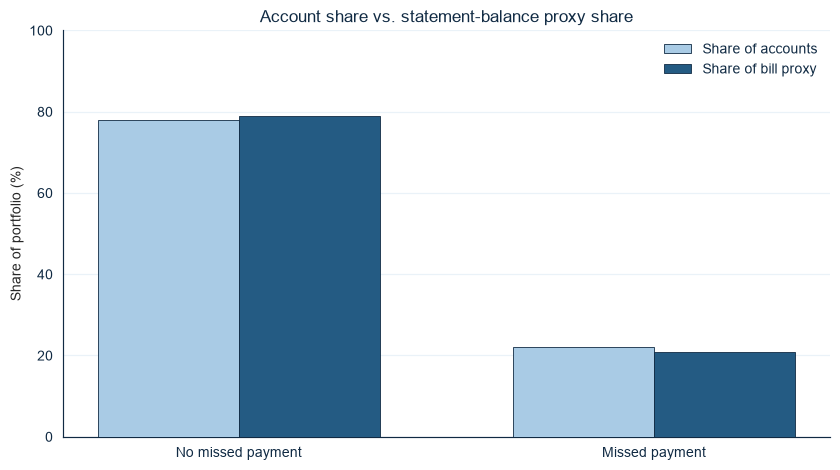

In [6]:
# 3.1 Portfolio profile and outcome distribution
target_profile = pd.DataFrame({
    "Outcome": ["No next-month missed payment", "Next-month missed payment"],
    "Accounts": [
        int(df[TARGET].eq(0).sum()),
        int(df[TARGET].eq(1).sum())
    ],
    "Account share": [
        df[TARGET].eq(0).mean(),
        df[TARGET].eq(1).mean()
    ],
    "Positive September bill proxy (NT$)": [
        df.loc[df[TARGET].eq(0), "POSITIVE_BILL_PROXY"].sum(),
        df.loc[df[TARGET].eq(1), "POSITIVE_BILL_PROXY"].sum()
    ]
})
target_profile["Bill proxy share"] = (
    target_profile["Positive September bill proxy (NT$)"]
    / target_profile["Positive September bill proxy (NT$)"].sum()
)
display(target_profile.style.format({
    "Accounts": "{:,.0f}",
    "Account share": "{:.1%}",
    "Positive September bill proxy (NT$)": "NT${:,.0f}",
    "Bill proxy share": "{:.1%}"
}))

fig, ax = plt.subplots(figsize=(8.5, 4.8))
x = np.arange(len(target_profile))
width = 0.34
ax.bar(
    x - width / 2,
    target_profile["Account share"] * 100,
    width,
    color=LIGHT_BLUE,
    edgecolor=DARK_NAVY,
    linewidth=0.6,
    label="Share of accounts",
    zorder=3
)
ax.bar(
    x + width / 2,
    target_profile["Bill proxy share"] * 100,
    width,
    color=DARK_BLUE,
    edgecolor=DARK_NAVY,
    linewidth=0.6,
    label="Share of bill proxy",
    zorder=3
)
ax.set_xticks(x)
ax.set_xticklabels(["No missed payment", "Missed payment"])
ax.set_ylabel("Share of portfolio (%)")
ax.set_title("Account share vs. statement-balance proxy share")
ax.legend(frameon=False)
ax.set_ylim(0, max(
    100,
    (target_profile[["Account share", "Bill proxy share"]].to_numpy().max() * 100) * 1.15
))
style_axis(ax)
plt.tight_layout()
plt.show()

,Month,Average bill (NT$),Average payment (NT$),Median bill (NT$),Median payment (NT$)
0,Apr,"NT$38,872","NT$5,216","NT$17,071","NT$1,500"
1,May,"NT$40,311","NT$4,799","NT$18,104","NT$1,500"
2,Jun,"NT$43,263","NT$4,826","NT$19,052","NT$1,500"
3,Jul,"NT$47,013","NT$5,226","NT$20,088","NT$1,800"
4,Aug,"NT$49,179","NT$5,921","NT$21,200","NT$2,009"
5,Sep,"NT$51,223","NT$5,664","NT$22,382","NT$2,100"


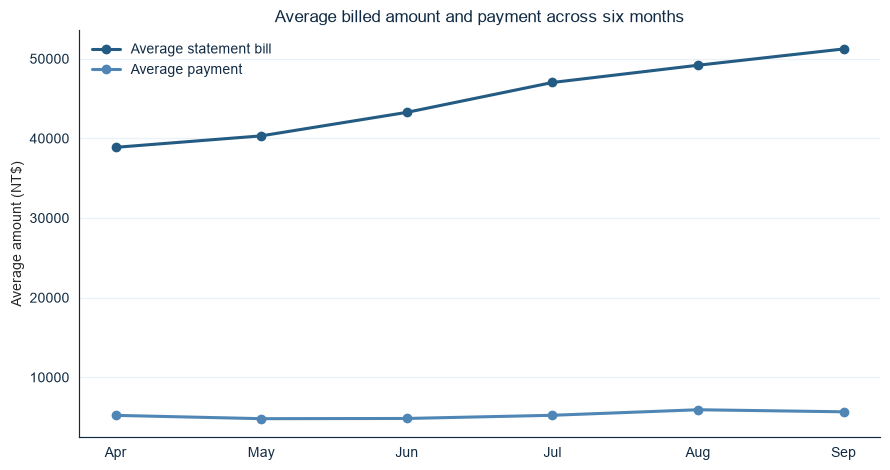

Reading note: the chart describes portfolio-level averages. It does not by itself measure whether an individual customer's payment was sufficient to cover the corresponding statement.


In [7]:
# 3.2 Six-month billing and payment behaviour
month_labels = ["Apr", "May", "Jun", "Jul", "Aug", "Sep"]
bill_month_cols = [f"BILL_AMT{i}" for i in range(6, 0, -1)]
payment_month_cols = [f"PAY_AMT{i}" for i in range(6, 0, -1)]

monthly_profile = pd.DataFrame({
    "Month": month_labels,
    "Average bill (NT$)": [df[col].mean() for col in bill_month_cols],
    "Average payment (NT$)": [df[col].mean() for col in payment_month_cols],
    "Median bill (NT$)": [df[col].median() for col in bill_month_cols],
    "Median payment (NT$)": [df[col].median() for col in payment_month_cols]
})
display(monthly_profile.style.format({
    "Average bill (NT$)": "NT${:,.0f}",
    "Average payment (NT$)": "NT${:,.0f}",
    "Median bill (NT$)": "NT${:,.0f}",
    "Median payment (NT$)": "NT${:,.0f}"
}))

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(
    monthly_profile["Month"],
    monthly_profile["Average bill (NT$)"],
    marker="o",
    linewidth=2.2,
    markersize=6,
    color=DARK_BLUE,
    label="Average statement bill",
    zorder=3
)
ax.plot(
    monthly_profile["Month"],
    monthly_profile["Average payment (NT$)"],
    marker="o",
    linewidth=2.2,
    markersize=6,
    color=MEDIUM_BLUE,
    label="Average payment",
    zorder=3
)
ax.set_ylabel("Average amount (NT$)")
ax.set_title("Average billed amount and payment across six months")
ax.legend(frameon=False)
style_axis(ax)
plt.tight_layout()
plt.show()

print(
    "Reading note: the chart describes portfolio-level averages. "
    "It does not by itself measure whether an individual customer's payment "
    "was sufficient to cover the corresponding statement."
)

,PAY_1,accounts,missed_payment_rate,missed_payment_accounts,account_share
0,-2,"2,759",13.2%,365,9.2%
1,-1,"5,686",16.8%,954,19.0%
2,0,"14,737",12.8%,"1,888",49.1%
3,1,"3,688",33.9%,"1,252",12.3%
4,2,"2,667",69.1%,"1,844",8.9%
5,3,322,75.8%,244,1.1%
6,4,76,68.4%,52,0.3%
7,5,26,50.0%,13,0.1%
8,6,11,54.5%,6,0.0%
9,7,9,77.8%,7,0.0%


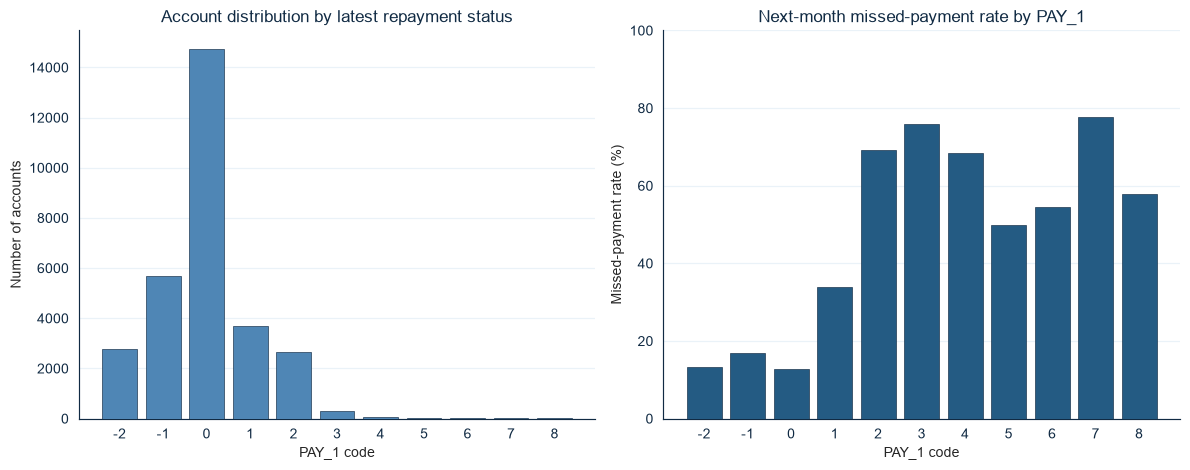

In [8]:
# 3.3 Latest repayment status and missed-payment rate by status
pay_status = (
    df.groupby("PAY_1", observed=True)[TARGET]
      .agg(accounts="size", missed_payment_rate="mean", missed_payment_accounts="sum")
      .reset_index()
      .sort_values("PAY_1")
)
pay_status["account_share"] = pay_status["accounts"] / len(df)
display(pay_status.style.format({
    "missed_payment_rate": "{:.1%}",
    "account_share": "{:.1%}",
    "accounts": "{:,.0f}",
    "missed_payment_accounts": "{:,.0f}"
}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].bar(
    pay_status["PAY_1"].astype(str),
    pay_status["accounts"],
    color=MEDIUM_BLUE,
    edgecolor=DARK_NAVY,
    linewidth=0.45,
    zorder=3
)
axes[0].set_title("Account distribution by latest repayment status")
axes[0].set_xlabel("PAY_1 code")
axes[0].set_ylabel("Number of accounts")
style_axis(axes[0])

axes[1].bar(
    pay_status["PAY_1"].astype(str),
    pay_status["missed_payment_rate"] * 100,
    color=DARK_BLUE,
    edgecolor=DARK_NAVY,
    linewidth=0.45,
    zorder=3
)
axes[1].set_title("Next-month missed-payment rate by PAY_1")
axes[1].set_xlabel("PAY_1 code")
axes[1].set_ylabel("Missed-payment rate (%)")
axes[1].set_ylim(0, 100)
style_axis(axes[1])

plt.tight_layout()
plt.show()

,BILL_TO_LIMIT_BAND,accounts,missed_payment_rate,missed_payment_accounts,account_share
0,No positive bill,"2,598",24.7%,643,8.7%
1,0–25%,"11,440",16.8%,"1,923",38.1%
2,25–50%,"3,588",21.7%,780,12.0%
3,50–75%,"3,579",26.0%,929,11.9%
4,75–100%,"6,680",25.8%,"1,725",22.3%
5,>100%,"2,115",30.1%,636,7.0%


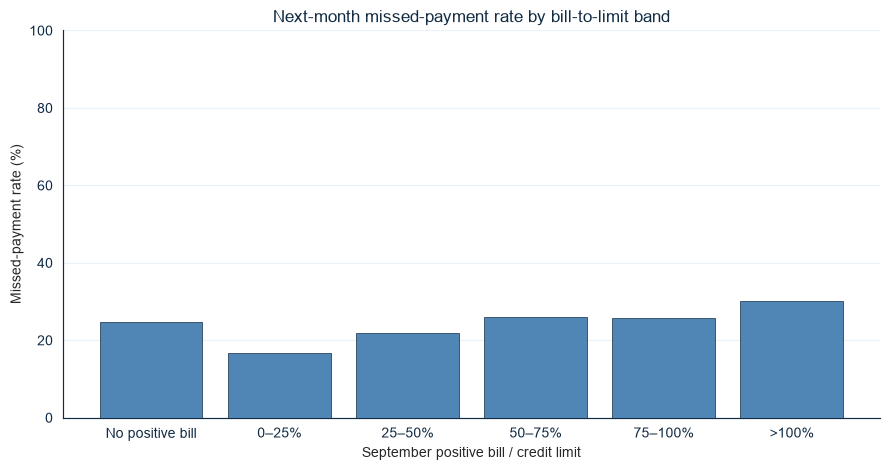

Bill-to-limit is an exposure/utilisation proxy only. Values above 100% are retained as a separate band rather than clipped.


In [9]:
# 3.4 Bill-to-limit profile and missed-payment rate
eda_util = df.loc[df["LIMIT_BAL"].gt(0)].copy()
eda_util["BILL_TO_LIMIT"] = (
    eda_util["POSITIVE_BILL_PROXY"] / eda_util["LIMIT_BAL"]
)
eda_util["BILL_TO_LIMIT_BAND"] = pd.cut(
    eda_util["BILL_TO_LIMIT"],
    bins=[-np.inf, 0, 0.25, 0.50, 0.75, 1.00, np.inf],
    labels=["No positive bill", "0–25%", "25–50%", "50–75%", "75–100%", ">100%"],
    right=True
)

util_profile = (
    eda_util.groupby("BILL_TO_LIMIT_BAND", observed=False)[TARGET]
            .agg(accounts="size", missed_payment_rate="mean", missed_payment_accounts="sum")
            .reset_index()
)
util_profile["account_share"] = util_profile["accounts"] / len(eda_util)
display(util_profile.style.format({
    "missed_payment_rate": "{:.1%}",
    "account_share": "{:.1%}",
    "accounts": "{:,.0f}",
    "missed_payment_accounts": "{:,.0f}"
}))

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(
    util_profile["BILL_TO_LIMIT_BAND"].astype(str),
    util_profile["missed_payment_rate"] * 100,
    color=MEDIUM_BLUE,
    edgecolor=DARK_NAVY,
    linewidth=0.5,
    zorder=3
)
ax.set_title("Next-month missed-payment rate by bill-to-limit band")
ax.set_xlabel("September positive bill / credit limit")
ax.set_ylabel("Missed-payment rate (%)")
ax.set_ylim(0, 100)
style_axis(ax)
plt.tight_layout()
plt.show()

print(
    "Bill-to-limit is an exposure/utilisation proxy only. Values above 100% "
    "are retained as a separate band rather than clipped."
)

### EDA synthesis: what the data tells us before modelling

Based on the exploratory data analysis, several key patterns emerge that heavily inform our predictive modelling and business strategy:

1. **Baseline Risk & Exposure:** The portfolio has a high baseline next-month missed-payment rate of 22.1%. Interestingly, while they make up 22.1% of accounts, they hold slightly less (20.9%) of the total statement-balance proxy. This suggests that at-risk accounts might have slightly lower average balances or credit limits compared to healthy accounts.
2. **Growing Debt Burden:** The six-month trajectory shows average billed amounts steadily increasing from ~NT$39k in April to over NT$51k in September, while average payments remain flat at around NT$5k. This widening gap indicates increasing portfolio utilisation and potential repayment stress over time, making historical payment-to-bill trajectories strong candidates for model features.
3. **Repayment Status as a Primary Signal:** `PAY_1` (the most recent repayment status) is highly discriminatory. Accounts with `PAY_1 <= 0` (current or revolving) have relatively lower risk (12-16%). However, the missed-payment rate jumps sharply to ~34% at `PAY_1 == 1` (one-month delay) and drastically exceeds 60% for `PAY_1 >= 2`. This confirms the operational logic of treating `PAY_1 >= 2` as a separate, high-risk collections queue, and isolating the early-warning population.
4. **Utilisation Risk:** The bill-to-limit (utilisation) bands demonstrate a clear risk gradient. Accounts with very low utilisation (0-25%) have the lowest risk (~16%). As utilisation increases towards 100% and beyond, the missed-payment rate climbs steadily up to 30%. The "No positive bill" segment also shows elevated risk (~24%), which often relates to dormant accounts, inactive revolvers, or specific fee-only balances, warranting the data-quality flags we applied earlier.

**Conclusion for Modelling:** The EDA confirms that recent repayment status and credit utilisation are strong, observable indicators of future missed payments. The predictive model should leverage the interplay between these historical payment patterns, debt accumulation, and limit utilisation to identify hidden risk specifically within the large, seemingly safe `PAY_1 <= 0` population.

This leads directly into the next operational question: **how much of the missed-payment population actually sits outside the assumed existing collections queue, and can those early-warning accounts be prioritised more effectively?**

## 4. Problem evidence: where is the early-warning gap?

The first test is operational: quantify how many next-month missed-payment cases appear outside the assumed existing queue.

**Interpretation:** a missed payment next month is an early-warning outcome in this dataset. It does not mean that every affected account will progress to serious delinquency or become a credit loss.

In [10]:
# 3.1 H1 — quantify the coverage gap
queue_mask = df["PAY_1"] >= 2
watch_mask = df["PAY_1"] == 1
early_mask = df["PAY_1"] <= 0

def safe_share(numerator, denominator):
    return numerator / denominator if denominator else np.nan

total_missed = int(df[TARGET].sum())
total_missed_bill_proxy = df.loc[
    df[TARGET].eq(1), "POSITIVE_BILL_PROXY"
].sum()

segment_masks = {
    "Existing queue (PAY_1 >= 2)": queue_mask,
    "One-month delay watch (PAY_1 == 1)": watch_mask,
    "Not yet delinquent (PAY_1 <= 0)": early_mask
}

h1_rows = []
for segment_name, mask in segment_masks.items():
    missed = df.loc[mask & df[TARGET].eq(1)]
    h1_rows.append({
        "Population": segment_name,
        "Accounts": int(mask.sum()),
        "Missed-payment accounts": int(df.loc[mask, TARGET].sum()),
        "Missed-payment rate": df.loc[mask, TARGET].mean(),
        "Share of all missed-payment accounts": safe_share(
            df.loc[mask, TARGET].sum(), total_missed
        ),
        "Missed-payment bill proxy (NT$)": missed["POSITIVE_BILL_PROXY"].sum(),
        "Share of missed-payment bill proxy": safe_share(
            missed["POSITIVE_BILL_PROXY"].sum(), total_missed_bill_proxy
        )
    })

h1 = pd.DataFrame(h1_rows)
display(h1.style.format({
    "Missed-payment rate": "{:.1%}",
    "Share of all missed-payment accounts": "{:.1%}",
    "Missed-payment bill proxy (NT$)": "NT${:,.0f}",
    "Share of missed-payment bill proxy": "{:.1%}"
}))

eligible_mask = (
    early_mask
    & df["POSITIVE_BILL_PROXY"].gt(0)
    & ~df["DORMANT_6M"]
)
print(f"Eligible early-warning accounts: {int(eligible_mask.sum()):,}")
print(
    "Missed-payment rate in eligible early-warning population: "
    f"{df.loc[eligible_mask, TARGET].mean():.1%}"
)

,Population,Accounts,Missed-payment accounts,Missed-payment rate,Share of all missed-payment accounts,Missed-payment bill proxy (NT$),Share of missed-payment bill proxy
0,Existing queue (PAY_1 >= 2),3130,2177,69.6%,32.8%,"NT$137,416,073",42.7%
1,One-month delay watch (PAY_1 == 1),3688,1252,33.9%,18.9%,"NT$38,341,713",11.9%
2,Not yet delinquent (PAY_1 <= 0),23182,3207,13.8%,48.3%,"NT$146,195,823",45.4%


Eligible early-warning accounts: 22,273
Missed-payment rate in eligible early-warning population: 13.6%


### H1 interpretation

Use the table above to establish whether a meaningful share of missed-payment cases sits outside the assumed queue. The early-warning proposal should focus on the eligible `PAY_1 <= 0` population; the `PAY_1 == 1` group remains a separate watch segment.

In [11]:
# 3.2 H2 — compare behavioural signals inside the early-warning population
early = df.loc[early_mask].copy()
prior_pay_cols = [f"PAY_{month}" for month in range(2, 7)]

early["PRIOR_2M_PLUS"] = early[prior_pay_cols].ge(2).any(axis=1)
early["PRIOR_POSITIVE_DELAY"] = early[prior_pay_cols].ge(1).any(axis=1)
early["ZERO_SEP_PAYMENT"] = early["PAY_AMT1"].eq(0)
early["HIGH_BILL_TO_LIMIT"] = (
    early["LIMIT_BAL"].gt(0)
    & (early["BILL_AMT1"] / early["LIMIT_BAL"]).ge(0.8)
)

signal_definitions = {
    "Prior 2+ month delinquency": "PRIOR_2M_PLUS",
    "Any prior positive delinquency code": "PRIOR_POSITIVE_DELAY",
    "Zero September payment amount": "ZERO_SEP_PAYMENT",
    "September bill / credit limit >= 80%": "HIGH_BILL_TO_LIMIT"
}

signal_rows = []
for signal_label, signal_col in signal_definitions.items():
    for signal_value, group_label in [(True, "Yes"), (False, "No")]:
        group = early.loc[early[signal_col].eq(signal_value)]
        signal_rows.append({
            "Signal": signal_label,
            "Group": group_label,
            "Accounts": len(group),
            "Missed-payment accounts": int(group[TARGET].sum()),
            "Missed-payment rate": group[TARGET].mean()
        })

signal_table = pd.DataFrame(signal_rows)
display(signal_table.pivot(
    index="Signal",
    columns="Group",
    values=["Accounts", "Missed-payment accounts", "Missed-payment rate"]
).style.format({
    ("Missed-payment rate", "No"): "{:.1%}",
    ("Missed-payment rate", "Yes"): "{:.1%}"
}))

# Dormant-account audit: data-definition review only.
dormant = df.loc[df["DORMANT_6M"]]
print(
    f"Dormant-pattern accounts: {len(dormant):,} "
    f"| next-month missed-payment rate: {dormant[TARGET].mean():.1%}"
)
display(
    dormant["PAY_1"].value_counts(dropna=False)
                  .rename_axis("PAY_1 code")
                  .reset_index(name="Accounts")
)

Dormant-pattern accounts: 860 | next-month missed-payment rate: 36.9%


,PAY_1 code,Accounts
0,1,540
1,-2,320


### Root-cause interpretation: predictive signals, not causal drivers

The analysis should distinguish three operational groups:

- **Existing delinquency:** continue the issuer's current collections route.
- **One-month delay:** monitor separately; it is a transition/watch group.
- **Not yet delinquent:** assess whether prior repayment status, payment amount, and bill-to-limit patterns help identify elevated next-month risk.

The behavioural comparisons are associations. They do not prove why a customer missed payment. Dormant-pattern records are a data-definition issue and should be excluded from automated outreach until validated.

## 5. Proof of concept: can we rank early-warning accounts?

### Modelling design

- Predict the dataset's next-month missed-payment label.
- Use only September-close and prior-month information.
- Include `AGE` and `EDUCATION` as predictors to capture life-stage and potential financial literacy signals.
- Exclude `SEX` and `MARRIAGE` to avoid discriminatory and personal bias in operational decisions.
- Treat repayment-status codes as categorical states, not a continuous numeric scale.
- Keep identical predictor profiles in one data split to reduce duplicate-profile leakage.
- Evaluate once on a held-out test set.

A single HistGradientBoosting model is used. The purpose is to test whether the model improves operational ranking, not to run a large model bake-off.

In [12]:
# 4.1 Feature engineering and grouped train/validation/test split
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss
)

RANDOM_STATE = 42
TARGET = "DEFAULT"
PAY_COLS = [f"PAY_{month}" for month in range(1, 7)]

model_df = df.copy()
prior_pay_cols = [f"PAY_{month}" for month in range(2, 7)]  # defined here so this cell is self-contained

categorical_features = PAY_COLS.copy() + ["EDUCATION"]
for column in categorical_features:
    model_df[column] = model_df[column].astype(str)

model_df["BILL_TO_LIMIT_SEP"] = np.where(
    model_df["LIMIT_BAL"].gt(0),
    model_df["BILL_AMT1"] / model_df["LIMIT_BAL"],
    np.nan
)
model_df["MEAN_BILL_TO_LIMIT_6M"] = np.where(
    model_df["LIMIT_BAL"].gt(0),
    model_df[BILL_COLS].mean(axis=1) / model_df["LIMIT_BAL"],
    np.nan
)
model_df["MAX_PRIOR_DELAY"] = (
    df[prior_pay_cols].clip(lower=0).max(axis=1)
)
model_df["COUNT_PRIOR_2M_PLUS"] = (
    df[prior_pay_cols].ge(2).sum(axis=1)
)
model_df["COUNT_PRIOR_DELAY"] = (
    df[prior_pay_cols].ge(1).sum(axis=1)
)
model_df["ZERO_PAYMENT_MONTHS"] = df[PAYMENT_COLS].eq(0).sum(axis=1)
model_df["LOG_TOTAL_PAYMENT_6M"] = np.log1p(
    df[PAYMENT_COLS].clip(lower=0).sum(axis=1)
)
model_df["LOG_POSITIVE_BILL"] = np.log1p(df["POSITIVE_BILL_PROXY"])
model_df["LOG_LIMIT_BAL"] = np.log1p(df["LIMIT_BAL"].clip(lower=0))

numeric_features = [
    "BILL_TO_LIMIT_SEP",
    "MEAN_BILL_TO_LIMIT_6M",
    "MAX_PRIOR_DELAY",
    "COUNT_PRIOR_2M_PLUS",
    "COUNT_PRIOR_DELAY",
    "ZERO_PAYMENT_MONTHS",
    "LOG_TOTAL_PAYMENT_6M",
    "LOG_POSITIVE_BILL",
    "LOG_LIMIT_BAL",
    "AGE"
]
feature_cols = categorical_features + numeric_features

X = model_df[feature_cols].copy()
y = model_df[TARGET].to_numpy(dtype=int)
groups = profile_id.to_numpy()

# Approximately 71% train, 14% validation, 14% test.
outer_split = StratifiedGroupKFold(
    n_splits=7, shuffle=True, random_state=RANDOM_STATE
)
trainval_idx, test_idx = next(
    outer_split.split(X, y, groups=groups)
)

inner_split = StratifiedGroupKFold(
    n_splits=6, shuffle=True, random_state=RANDOM_STATE + 1
)
train_rel, val_rel = next(
    inner_split.split(
        X.iloc[trainval_idx],
        y[trainval_idx],
        groups=groups[trainval_idx]
    )
)
train_idx = trainval_idx[train_rel]
val_idx = trainval_idx[val_rel]

train_groups = set(groups[train_idx])
val_groups = set(groups[val_idx])
test_groups = set(groups[test_idx])
assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Accounts": [len(train_idx), len(val_idx), len(test_idx)],
    "Missed-payment rate": [
        y[train_idx].mean(),
        y[val_idx].mean(),
        y[test_idx].mean()
    ]
})
display(split_summary.style.format({"Missed-payment rate": "{:.1%}"}))

,Split,Accounts,Missed-payment rate
0,Train,21428,22.1%
1,Validation,4285,22.1%
2,Test,4287,22.1%


In [13]:
# 4.2 Train one model and assess validation performance
preprocessor = ColumnTransformer([
    (
        "repayment_status",
        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        categorical_features
    ),
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numeric_features
    )
])

model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=180,
        learning_rate=0.05,
        max_leaf_nodes=20,
        min_samples_leaf=40,
        l2_regularization=2.0,
        early_stopping=False,
        random_state=RANDOM_STATE
    ))
])

model.fit(X.iloc[train_idx], y[train_idx])

p_val = model.predict_proba(X.iloc[val_idx])[:, 1]
validation_metrics = pd.DataFrame([{
    "ROC-AUC": roc_auc_score(y[val_idx], p_val),
    "PR-AUC": average_precision_score(y[val_idx], p_val),
    "Brier score": brier_score_loss(y[val_idx], p_val),
    "Missed-payment prevalence": y[val_idx].mean()
}])
display(validation_metrics.style.format("{:.4f}"))

,ROC-AUC,PR-AUC,Brier score,Missed-payment prevalence
0,0.7758,0.5572,0.1361,0.2212


,ROC-AUC,PR-AUC,Brier score,Missed-payment prevalence
0,0.7787,0.5467,0.1365,0.2211


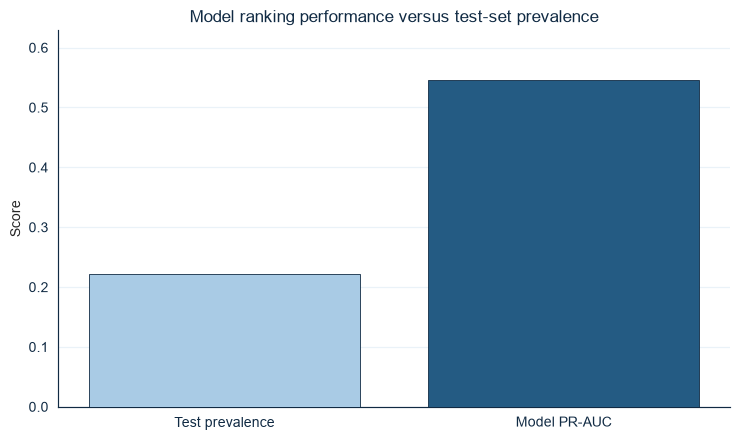

PR-AUC above prevalence indicates better-than-random ranking on this held-out sample; it does not establish profitability.


In [14]:
# 4.3 Final held-out test evaluation
p_test = model.predict_proba(X.iloc[test_idx])[:, 1]

test_metrics = pd.DataFrame([{
    "ROC-AUC": roc_auc_score(y[test_idx], p_test),
    "PR-AUC": average_precision_score(y[test_idx], p_test),
    "Brier score": brier_score_loss(y[test_idx], p_test),
    "Missed-payment prevalence": y[test_idx].mean()
}])
display(test_metrics.style.format("{:.4f}"))

test_pr_auc = average_precision_score(y[test_idx], p_test)
test_prevalence = y[test_idx].mean()

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.bar(
    ["Test prevalence", "Model PR-AUC"],
    [test_prevalence, test_pr_auc],
    color=[LIGHT_BLUE, DARK_BLUE],
    edgecolor=DARK_NAVY,
    linewidth=0.6,
    zorder=3
)
ax.set_ylabel("Score")
ax.set_title("Model ranking performance versus test-set prevalence")
ax.set_ylim(0, max(0.6, test_pr_auc * 1.15))
style_axis(ax)
plt.tight_layout()
plt.show()

print(
    "PR-AUC above prevalence indicates better-than-random ranking "
    "on this held-out sample; it does not establish profitability."
)

## 6. Business test: does the model add value beyond simple ranking rules?

The primary test compares prioritisation methods inside the eligible early-warning population at **equal contact capacity (top 30%)**:

1. Keep only test accounts with `PAY_1 <= 0`, positive statement-balance proxy, and no dormant-pattern flag.
2. **Model score only:** ranks by predicted next-month missed-payment probability (pure risk ranking).
3. **Model score x bill proxy (P.A.C.E. priority):** ranks by expected exposure at risk, i.e. probability weighted by statement balance.
4. **Balance-only:** ranks by statement-balance proxy alone (the simple exposure benchmark).
5. **Simple behavioural rule:** counts prior-month delays plus a zero-payment flag (no model required).
6. Compare identified missed-payment accounts and the statement-balance proxy observed in the held-out test sample.

> **How to read the trade-off:** ranking by *risk* finds more missed-payment accounts per contact, while ranking by *expected exposure* concentrates outreach on larger balances. They answer different questions, so both are reported. Results are **incremental identification**, not avoided loss. The model score is not regulatory PD or IFRS 9 PD.

,Strategy,Accounts selected,Missed-payment accounts identified,Missed-payment rate in selected group,Recall of eligible missed-payment accounts,Missed-payment bill proxy captured (NT$),Share of eligible missed-payment bill proxy captured,Model-score-weighted bill proxy (NT$)
0,Model score × bill proxy,945,131,13.9%,30.7%,"NT$16,114,017",79.4%,"NT$16,578,181"
1,Balance-only ranking,945,96,10.2%,22.5%,"NT$15,287,778",75.3%,"NT$15,322,418"


Eligible test accounts: 3,151
Contact capacity: 30% (945 accounts)
Incremental missed-payment accounts identified: +35
Incremental observed bill proxy captured: NT$+826,239
Incremental share of missed-payment bill proxy: +4.1 pp
Difference in model-score-weighted bill proxy: NT$+1,255,763
Readout: model ranking captures more observed missed-payment bill proxy than balance-only ranking.


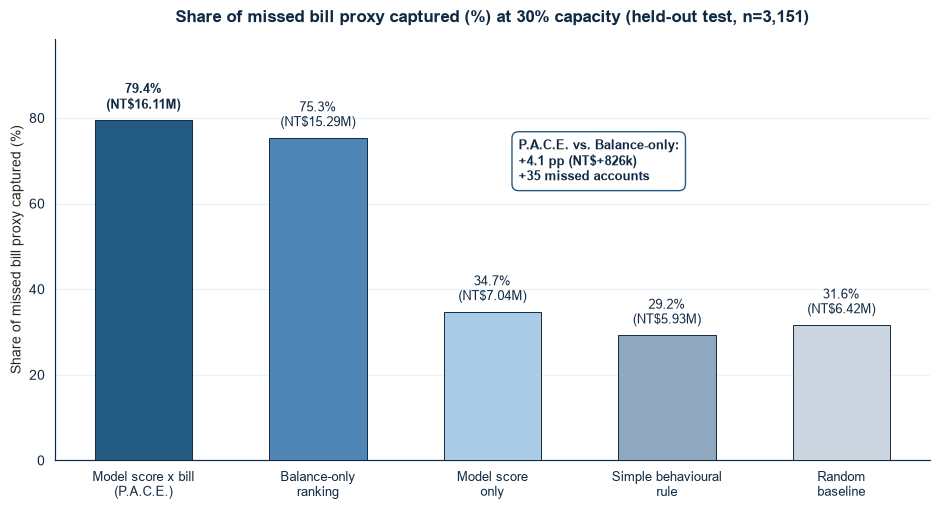

In [ ]:
# 5.1 Equal-capacity comparison in the early-warning population
CONTACT_CAPACITY = 0.30  # Explicit operating scenario; not tuned on the test set.

test_view = df.iloc[test_idx].copy()
test_view["MODEL_SCORE"] = p_test
test_view["MODEL_PRIORITY_SCORE"] = (
    test_view["MODEL_SCORE"] * test_view["POSITIVE_BILL_PROXY"]
)

eligible_test = test_view.loc[
    test_view["PAY_1"].le(0)
    & test_view["POSITIVE_BILL_PROXY"].gt(0)
    & ~test_view["DORMANT_6M"]
].copy()

if eligible_test.empty:
    raise ValueError("No eligible early-warning accounts in the test sample.")

n_select = max(
    1, int(np.floor(len(eligible_test) * CONTACT_CAPACITY))
)

model_selected = eligible_test.nlargest(
    n_select, "MODEL_PRIORITY_SCORE"
)
balance_selected = eligible_test.nlargest(
    n_select, "POSITIVE_BILL_PROXY"
)

def selection_metrics(selected, full_eligible, strategy_name):
    total_missed_bill_proxy = full_eligible.loc[
        full_eligible[TARGET].eq(1), "POSITIVE_BILL_PROXY"
    ].sum()
    selected_missed = selected.loc[selected[TARGET].eq(1)]
    captured_bill_proxy = selected_missed["POSITIVE_BILL_PROXY"].sum()

    return {
        "Strategy": strategy_name,
        "Accounts selected": len(selected),
        "Missed-payment accounts identified": int(selected[TARGET].sum()),
        "Missed-payment rate in selected group": selected[TARGET].mean(),
        "Recall of eligible missed-payment accounts": (
            selected[TARGET].sum() / full_eligible[TARGET].sum()
            if full_eligible[TARGET].sum() else np.nan
        ),
        "Missed-payment bill proxy captured (NT$)": captured_bill_proxy,
        "Share of eligible missed-payment bill proxy captured": (
            captured_bill_proxy / total_missed_bill_proxy
            if total_missed_bill_proxy else np.nan
        ),
        "Model-score-weighted bill proxy (NT$)": (
            selected["MODEL_SCORE"] * selected["POSITIVE_BILL_PROXY"]
        ).sum()
    }

comparison = pd.DataFrame([
    selection_metrics(
        model_selected, eligible_test, "Model score × bill proxy"
    ),
    selection_metrics(
        balance_selected, eligible_test, "Balance-only ranking"
    )
])

display(comparison.style.format({
    "Missed-payment rate in selected group": "{:.1%}",
    "Recall of eligible missed-payment accounts": "{:.1%}",
    "Missed-payment bill proxy captured (NT$)": "NT${:,.0f}",
    "Share of eligible missed-payment bill proxy captured": "{:.1%}",
    "Model-score-weighted bill proxy (NT$)": "NT${:,.0f}"
}))

model_row = comparison.iloc[0]
balance_row = comparison.iloc[1]

incremental_missed_accounts = (
    model_row["Missed-payment accounts identified"]
    - balance_row["Missed-payment accounts identified"]
)
incremental_observed_bill_proxy = (
    model_row["Missed-payment bill proxy captured (NT$)"]
    - balance_row["Missed-payment bill proxy captured (NT$)"]
)
incremental_capture_pp = 100 * (
    model_row["Share of eligible missed-payment bill proxy captured"]
    - balance_row["Share of eligible missed-payment bill proxy captured"]
)
incremental_score_weighted_proxy = (
    model_row["Model-score-weighted bill proxy (NT$)"]
    - balance_row["Model-score-weighted bill proxy (NT$)"]
)

print(f"Eligible test accounts: {len(eligible_test):,}")
print(f"Contact capacity: {CONTACT_CAPACITY:.0%} ({n_select:,} accounts)")
print(f"Incremental missed-payment accounts identified: {incremental_missed_accounts:+,.0f}")
print(f"Incremental observed bill proxy captured: NT${incremental_observed_bill_proxy:+,.0f}")
print(f"Incremental share of missed-payment bill proxy: {incremental_capture_pp:+.1f} pp")
print(
    "Difference in model-score-weighted bill proxy: "
    f"NT${incremental_score_weighted_proxy:+,.0f}"
)

if incremental_observed_bill_proxy > 0:
    print("Readout: model ranking captures more observed missed-payment bill proxy than balance-only ranking.")
elif incremental_observed_bill_proxy < 0:
    print("Readout: balance-only ranking captures more observed missed-payment bill proxy; incremental model value is not demonstrated.")
else:
    print("Readout: both ranking methods capture the same observed missed-payment bill proxy.")

rng_51 = np.random.default_rng(RANDOM_STATE)
score_only_selected = eligible_test.nlargest(n_select, "MODEL_SCORE")
rule_priority = (
    eligible_test[prior_pay_cols].ge(1).sum(axis=1).to_numpy()
    + eligible_test["PAY_AMT1"].eq(0).to_numpy().astype(int)
    + rng_51.random(len(eligible_test)) * 0.01
)
rule_selected = eligible_test.iloc[np.argsort(-rule_priority)[:n_select]]
random_selected = eligible_test.iloc[rng_51.permutation(len(eligible_test))[:n_select]]

proxy_chart_df = pd.DataFrame([
    selection_metrics(model_selected, eligible_test, "Model score x bill\n(P.A.C.E.)"),
    selection_metrics(balance_selected, eligible_test, "Balance-only\nranking"),
    selection_metrics(score_only_selected, eligible_test, "Model score\nonly"),
    selection_metrics(rule_selected, eligible_test, "Simple behavioural\nrule"),
    selection_metrics(random_selected, eligible_test, "Random\nbaseline"),
])
shares_pct = proxy_chart_df["Share of eligible missed-payment bill proxy captured"].to_numpy() * 100
proxies_m = proxy_chart_df["Missed-payment bill proxy captured (NT$)"].to_numpy() / 1e6

fig, ax = plt.subplots(figsize=(9.5, 5.2))
bar_colors = [DARK_BLUE, MEDIUM_BLUE, LIGHT_BLUE, "#8FA8BF", "#CBD5DF"]
x_pos = np.arange(len(proxy_chart_df))
bars = ax.bar(
    x_pos,
    shares_pct,
    color=bar_colors,
    edgecolor=DARK_NAVY,
    linewidth=0.7,
    width=0.56,
    zorder=3
)

for idx_b, (bar, share_v, proxy_v) in enumerate(zip(bars, shares_pct, proxies_m)):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        share_v + 1.8,
        f"{share_v:.1f}%\n(NT${proxy_v:.2f}M)",
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold" if idx_b == 0 else "normal",
        color=DARK_NAVY
    )

ax.text(
    2.15,
    max(shares_pct) * 0.88,
    f"P.A.C.E. vs. Balance-only:\n{incremental_capture_pp:+.1f} pp (NT${incremental_observed_bill_proxy/1e3:+,.0f}k)\n{incremental_missed_accounts:+,.0f} missed accounts",
    ha="left",
    va="center",
    fontsize=9.5,
    fontweight="bold",
    color=DARK_NAVY,
    bbox=dict(boxstyle="round,pad=0.5", fc="white", ec=DARK_BLUE, lw=1.0)
)

ax.set_xticks(x_pos)
ax.set_xticklabels(proxy_chart_df["Strategy"], fontsize=9.5)
ax.set_ylabel("Share of missed bill proxy captured (%)")
ax.set_title(
    f"Share of missed bill proxy captured (%) at {CONTACT_CAPACITY:.0%} capacity (held-out test, n={len(eligible_test):,})",
    fontsize=12,
    fontweight="bold",
    color=DARK_NAVY,
    pad=12
)
ax.set_ylim(0, max(shares_pct) * 1.24)
style_axis(ax)
plt.tight_layout()
plt.show()


### 6.1 Model quality *inside the population P.A.C.E. actually targets*

The headline ROC-AUC in Section 5 is computed on **all** test accounts, which are dominated by `PAY_1 >= 2` accounts that are easy to rank. P.A.C.E. only acts on `PAY_1 <= 0`, so the metrics below are the ones that matter for the proposal: discrimination, calibration, and top-30% lift **within the eligible population only**.

In [16]:
# 5.1a Model quality restricted to the eligible early-warning population
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

elig_y = eligible_test[TARGET].to_numpy()
elig_s = eligible_test["MODEL_SCORE"].to_numpy()
elig_base = elig_y.mean()

n_top = int(np.floor(len(eligible_test) * CONTACT_CAPACITY))
top_idx = np.argsort(-elig_s)[:n_top]

elig_quality = pd.DataFrame([{
    "Eligible test accounts": len(eligible_test),
    "Base missed-payment rate": elig_base,
    "ROC-AUC (all test accounts)": roc_auc_score(y[test_idx], p_test),
    "ROC-AUC (eligible only)": roc_auc_score(elig_y, elig_s),
    "PR-AUC (eligible only)": average_precision_score(elig_y, elig_s),
    "Mean predicted score": elig_s.mean(),
    "Brier (model)": brier_score_loss(elig_y, elig_s),
    "Brier (constant base rate)": brier_score_loss(elig_y, np.full(len(elig_y), elig_base)),
    "Top-30% hit rate by score": elig_y[top_idx].mean(),
    "Top-30% lift by score": elig_y[top_idx].mean() / elig_base,
}]).T.rename(columns={0: "Value"})
elig_quality["Value"] = [
    f"{len(eligible_test):,}", f"{elig_base:.1%}",
    f"{roc_auc_score(y[test_idx], p_test):.3f}", f"{roc_auc_score(elig_y, elig_s):.3f}",
    f"{average_precision_score(elig_y, elig_s):.3f} (base {elig_base:.3f})",
    f"{elig_s.mean():.3f} (observed {elig_base:.3f})",
    f"{brier_score_loss(elig_y, elig_s):.4f}",
    f"{brier_score_loss(elig_y, np.full(len(elig_y), elig_base)):.4f}",
    f"{elig_y[top_idx].mean():.1%}", f"{elig_y[top_idx].mean() / elig_base:.2f}x"
]
display(elig_quality)
print(
    "Interpretation: discrimination inside the eligible population is clearly lower than the all-account AUC, "
    "but the score is well calibrated and gives meaningful top-30% lift over the base rate."
)


,Value
Eligible test accounts,"3,151"
Base missed-payment rate,13.6%
ROC-AUC (all test accounts),0.779
ROC-AUC (eligible only),0.675
PR-AUC (eligible only),0.248 (base 0.136)
Mean predicted score,0.134 (observed 0.136)
Brier (model),0.1116
Brier (constant base rate),0.1171
Top-30% hit rate by score,23.1%
Top-30% lift by score,1.70x


Interpretation: discrimination inside the eligible population is clearly lower than the all-account AUC, but the score is well calibrated and gives meaningful top-30% lift over the base rate.


### Statistical Significance Testing (Bootstrapping)

To check that the incremental benefit of the P.A.C.E. priority score over balance-only ranking is not just noise in one test split, we bootstrap the eligible test set 1,000 times, re-running the top-30% selection for both strategies each time. We report a 95% confidence interval and a one-sided empirical p-value.

> **Reading guidance:** when the 95% CI for the incremental bill proxy touches zero, treat the dollar result as *directionally positive but not conclusive on this single split*. Section 6.2 repeats the comparison over several independent grouped splits, which is stronger evidence than one bootstrap.

--- Bootstrapping Results (1000 iterations) ---
Incremental Accounts Identified:
  Mean: 37.0
  95% CI: [23, 51]
  p-value (<= 0): 0.000 (Significant at alpha=0.05)

Incremental Bill Proxy Captured (NT$):
  Mean: NT$926,678
  95% CI: [NT$-54,492, NT$1,782,023]
  p-value (<= 0): 0.036 (Significant at alpha=0.05)


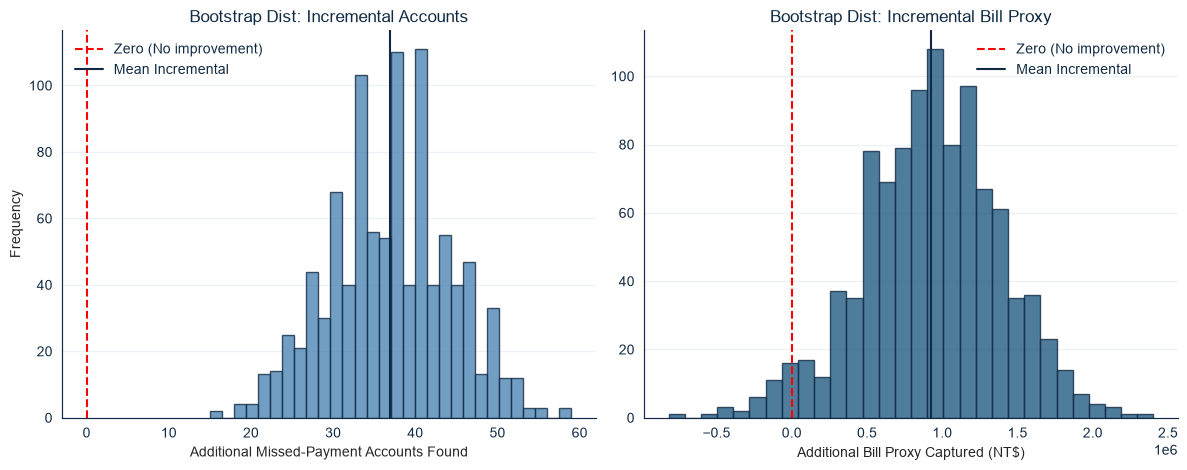

In [17]:
# 5.1b Statistical Significance Test (Bootstrapping) for Incremental Value
np.random.seed(42)
n_bootstraps = 1000

boot_inc_accounts = []
boot_inc_proxy = []

# Run bootstrap iterations
for i in range(n_bootstraps):
    # Resample the eligible test set with replacement
    sample = eligible_test.sample(frac=1.0, replace=True, random_state=i)

    n_sel = max(1, int(np.floor(len(sample) * CONTACT_CAPACITY)))

    # Select top 30% for both strategies in this bootstrap sample
    mod_sel = sample.nlargest(n_sel, "MODEL_PRIORITY_SCORE")
    bal_sel = sample.nlargest(n_sel, "POSITIVE_BILL_PROXY")

    # Calculate captured metrics
    mod_acc = mod_sel[TARGET].sum()
    mod_prx = mod_sel.loc[mod_sel[TARGET].eq(1), "POSITIVE_BILL_PROXY"].sum()

    bal_acc = bal_sel[TARGET].sum()
    bal_prx = bal_sel.loc[bal_sel[TARGET].eq(1), "POSITIVE_BILL_PROXY"].sum()

    # Store incremental results
    boot_inc_accounts.append(mod_acc - bal_acc)
    boot_inc_proxy.append(mod_prx - bal_prx)

boot_inc_accounts = np.array(boot_inc_accounts)
boot_inc_proxy = np.array(boot_inc_proxy)

# Calculate 95% Confidence Intervals
ci_acc = np.percentile(boot_inc_accounts, [2.5, 97.5])
ci_prx = np.percentile(boot_inc_proxy, [2.5, 97.5])

# Calculate empirical p-value (probability that incremental value is <= 0)
p_val_acc = np.mean(boot_inc_accounts <= 0)
p_val_prx = np.mean(boot_inc_proxy <= 0)

print(f"--- Bootstrapping Results ({n_bootstraps} iterations) ---")
print(f"Incremental Accounts Identified:")
print(f"  Mean: {boot_inc_accounts.mean():.1f}")
print(f"  95% CI: [{ci_acc[0]:.0f}, {ci_acc[1]:.0f}]")
print(f"  p-value (<= 0): {p_val_acc:.3f} {'(Significant at alpha=0.05)' if p_val_acc < 0.05 else '(Not significant)'}\n")

print(f"Incremental Bill Proxy Captured (NT$):")
print(f"  Mean: NT${boot_inc_proxy.mean():,.0f}")
print(f"  95% CI: [NT${ci_prx[0]:,.0f}, NT${ci_prx[1]:,.0f}]")
print(f"  p-value (<= 0): {p_val_prx:.3f} {'(Significant at alpha=0.05)' if p_val_prx < 0.05 else '(Not significant)'}")

# Plotting the distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

axes[0].hist(boot_inc_accounts, bins=30, color=MEDIUM_BLUE, edgecolor=DARK_NAVY, alpha=0.8)
axes[0].axvline(0, color='red', linestyle='--', linewidth=1.5, label='Zero (No improvement)')
axes[0].axvline(boot_inc_accounts.mean(), color=DARK_NAVY, linestyle='-', linewidth=1.5, label='Mean Incremental')
axes[0].set_title('Bootstrap Dist: Incremental Accounts')
axes[0].set_xlabel('Additional Missed-Payment Accounts Found')
axes[0].set_ylabel('Frequency')
axes[0].legend(frameon=False)
style_axis(axes[0])

axes[1].hist(boot_inc_proxy, bins=30, color=DARK_BLUE, edgecolor=DARK_NAVY, alpha=0.8)
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.5, label='Zero (No improvement)')
axes[1].axvline(boot_inc_proxy.mean(), color=DARK_NAVY, linestyle='-', linewidth=1.5, label='Mean Incremental')
axes[1].set_title('Bootstrap Dist: Incremental Bill Proxy')
axes[1].set_xlabel('Additional Bill Proxy Captured (NT$)')
axes[1].legend(frameon=False)
style_axis(axes[1])

plt.tight_layout()
plt.show()

### 6.2 Robustness: multiple grouped splits, stronger benchmarks, and a fairness ablation

A single train/test split can flatter or hurt any strategy, and library versions can change which accounts land in the test set. Here the whole pipeline is re-fitted on **8 independent grouped splits** (identical-profile accounts always stay together). For each split we compare four ranking rules at the same 30% capacity and report **mean ± standard deviation**:

- **Model score only**, **model score x bill proxy** (P.A.C.E. priority), **balance-only**, and a **simple behavioural rule** (prior delays + zero September payment, no model).
- A **random** ranking as the floor.

The same loop also reports a **logistic-regression baseline** and an **ablation without `AGE` and `EDUCATION`**, so the governance decision on demographic-adjacent features can be made with evidence.

Strategy comparison at 30% capacity - mean ± sd over 8 grouped splits


,Hit rate,Lift vs base,Missed accounts found,Share of missed bill proxy
Strategy,,,,
Model score only,22.8% ± 1.1%,1.70x ± 0.09,218 ± 11,36.5% ± 3.9%
Model score x bill (P.A.C.E.),14.1% ± 0.9%,1.05x ± 0.05,135 ± 9,81.0% ± 2.3%
Balance-only,10.3% ± 1.0%,0.77x ± 0.06,98 ± 10,75.7% ± 2.7%
Simple behavioural rule,19.2% ± 0.9%,1.43x ± 0.08,183 ± 8,31.8% ± 3.9%
Random,13.9% ± 1.2%,1.04x ± 0.08,133 ± 12,30.2% ± 4.5%


Model comparison inside the eligible population


,AUC (eligible),PR-AUC (eligible),Top-30% lift
Model,,,
HGB (all features),0.686 ± 0.016,0.263 ± 0.020,1.70x ± 0.09
LR baseline,0.673 ± 0.015,0.253 ± 0.015,1.72x ± 0.08
HGB (no AGE/EDUCATION),0.685 ± 0.017,0.262 ± 0.022,1.70x ± 0.08


P.A.C.E. priority vs balance-only: +36 missed accounts (range 33 to 43), +NT$1,067,279 bill proxy (range NT$903,203 to NT$1,393,250); better in 8/8 splits.


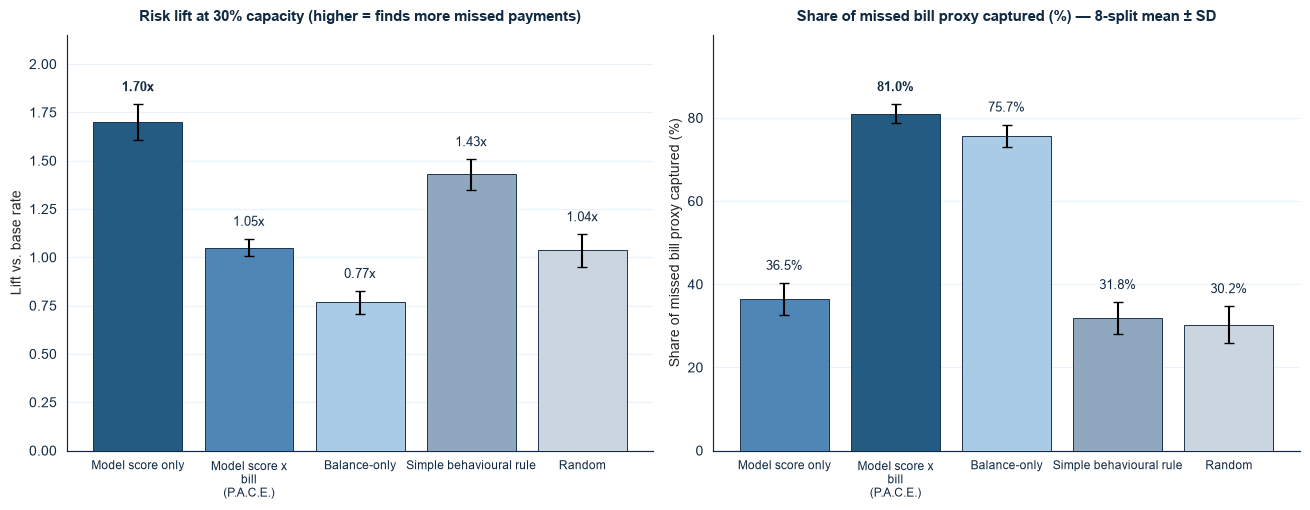

In [18]:
# 5.1c Multi-split robustness: strategies, LR baseline, and AGE/EDUCATION ablation
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

N_SPLITS_ROBUST = 8

def build_pipeline(cat_cols, num_cols, kind="hgb"):
    prep = ColumnTransformer([
        ("repayment_status", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")),
                              ("scaler", StandardScaler())]), num_cols)
    ])
    if kind == "hgb":
        est = HistGradientBoostingClassifier(
            max_iter=180, learning_rate=0.05, max_leaf_nodes=20, min_samples_leaf=40,
            l2_regularization=2.0, early_stopping=False, random_state=RANDOM_STATE)
    else:
        est = LogisticRegression(max_iter=2000)
    return Pipeline([("preprocess", prep), ("classifier", est)])

cat_noprot = [c for c in categorical_features if c != "EDUCATION"]
num_noprot = [c for c in numeric_features if c != "AGE"]

strategy_names = ["Model score only", "Model score x bill (P.A.C.E.)",
                  "Balance-only", "Simple behavioural rule", "Random"]
robust_rows, model_rows = [], []

for seed in range(N_SPLITS_ROBUST):
    outer = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=seed)
    tv, te = next(outer.split(X, y, groups=groups))
    fitted = {
        "HGB (all features)": (build_pipeline(categorical_features, numeric_features, "hgb"), feature_cols),
        "LR baseline": (build_pipeline(categorical_features, numeric_features, "lr"), feature_cols),
        "HGB (no AGE/EDUCATION)": (build_pipeline(cat_noprot, num_noprot, "hgb"), cat_noprot + num_noprot),
    }
    fold = df.iloc[te].copy()
    elig = (fold["PAY_1"].le(0) & fold["POSITIVE_BILL_PROXY"].gt(0) & ~fold["DORMANT_6M"]).to_numpy()
    fold_e = fold.loc[elig].copy()
    ye = fold_e[TARGET].to_numpy()
    n_k = int(np.floor(len(fold_e) * CONTACT_CAPACITY))
    bill = fold_e["POSITIVE_BILL_PROXY"].to_numpy()

    scores = {}
    for name, (pipe, cols) in fitted.items():
        pipe.fit(X.iloc[tv][cols], y[tv])
        pe = pipe.predict_proba(X.iloc[te][cols])[:, 1]
        scores[name] = pe[elig]
        model_rows.append({
            "Model": name, "Split": seed,
            "AUC (eligible)": roc_auc_score(ye, scores[name]),
            "PR-AUC (eligible)": average_precision_score(ye, scores[name]),
            "Top-30% lift": ye[np.argsort(-scores[name])[:n_k]].mean() / ye.mean()
        })

    s_hgb = scores["HGB (all features)"]
    rng = np.random.default_rng(seed)
    rule = (fold_e[prior_pay_cols].ge(1).sum(axis=1).to_numpy()
            + fold_e["PAY_AMT1"].eq(0).to_numpy().astype(int)
            + rng.random(len(fold_e)) * 0.01)
    rankers = {
        "Model score only": s_hgb,
        "Model score x bill (P.A.C.E.)": s_hgb * bill,
        "Balance-only": bill,
        "Simple behavioural rule": rule,
        "Random": rng.random(len(fold_e)),
    }
    total_proxy = (bill * ye).sum()
    for name, rk in rankers.items():
        sel = np.argsort(-rk)[:n_k]
        robust_rows.append({
            "Strategy": name, "Split": seed,
            "Hit rate": ye[sel].mean(), "Lift": ye[sel].mean() / ye.mean(),
            "Missed accounts found": int(ye[sel].sum()),
            "Share of missed bill proxy": (bill[sel] * ye[sel]).sum() / total_proxy,
            "Missed bill proxy (NT$)": (bill[sel] * ye[sel]).sum()
        })

robust_df = pd.DataFrame(robust_rows)
model_cmp = pd.DataFrame(model_rows)

def mean_sd(frame, group, col, fmt):
    g = frame.groupby(group, sort=False)[col]
    return g.mean().combine(g.std(), lambda m, s: fmt.format(m, s))

strategy_table = pd.DataFrame({
    "Hit rate": mean_sd(robust_df, "Strategy", "Hit rate", "{:.1%} ± {:.1%}"),
    "Lift vs base": mean_sd(robust_df, "Strategy", "Lift", "{:.2f}x ± {:.2f}"),
    "Missed accounts found": mean_sd(robust_df, "Strategy", "Missed accounts found", "{:.0f} ± {:.0f}"),
    "Share of missed bill proxy": mean_sd(robust_df, "Strategy", "Share of missed bill proxy", "{:.1%} ± {:.1%}"),
}).loc[strategy_names]
print(f"Strategy comparison at {CONTACT_CAPACITY:.0%} capacity - mean ± sd over {N_SPLITS_ROBUST} grouped splits")
display(strategy_table)

model_table = pd.DataFrame({
    "AUC (eligible)": mean_sd(model_cmp, "Model", "AUC (eligible)", "{:.3f} ± {:.3f}"),
    "PR-AUC (eligible)": mean_sd(model_cmp, "Model", "PR-AUC (eligible)", "{:.3f} ± {:.3f}"),
    "Top-30% lift": mean_sd(model_cmp, "Model", "Top-30% lift", "{:.2f}x ± {:.2f}"),
})
print("Model comparison inside the eligible population")
display(model_table)

pv = robust_df.pivot(index="Split", columns="Strategy")
inc_acc = pv["Missed accounts found"]["Model score x bill (P.A.C.E.)"] - pv["Missed accounts found"]["Balance-only"]
inc_prx = pv["Missed bill proxy (NT$)"]["Model score x bill (P.A.C.E.)"] - pv["Missed bill proxy (NT$)"]["Balance-only"]
print(
    f"P.A.C.E. priority vs balance-only: +{inc_acc.mean():.0f} missed accounts "
    f"(range {inc_acc.min():.0f} to {inc_acc.max():.0f}), "
    f"+NT${inc_prx.mean():,.0f} bill proxy (range NT${inc_prx.min():,.0f} to NT${inc_prx.max():,.0f}); "
    f"better in {int((inc_prx > 0).sum())}/{N_SPLITS_ROBUST} splits."
)
ROBUST_SUMMARY = {
    "inc_acc_mean": float(inc_acc.mean()), "inc_prx_mean": float(inc_prx.mean()),
    "wins": int((inc_prx > 0).sum())
}

fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.2))
panel_specs = [
    (
        axes[0],
        "Lift",
        "Risk lift at 30% capacity (higher = finds more missed payments)",
        1,
        "{:.2f}x",
        [DARK_BLUE, MEDIUM_BLUE, LIGHT_BLUE, "#8FA8BF", "#CBD5DF"],
        0
    ),
    (
        axes[1],
        "Share of missed bill proxy",
        "Share of missed bill proxy captured (%) — 8-split mean ± SD",
        100,
        "{:.1f}%",
        [MEDIUM_BLUE, DARK_BLUE, LIGHT_BLUE, "#8FA8BF", "#CBD5DF"],
        1
    )
]
g = robust_df.groupby("Strategy", sort=False)
x_idx = np.arange(len(strategy_names))
x_labels = [n.replace(" (", "\n(").replace(" x ", " x\n") for n in strategy_names]

for ax, col, title, scale, val_fmt, bar_cols, highlight_idx in panel_specs:
    m = g[col].mean().loc[strategy_names] * scale
    s_ = g[col].std().loc[strategy_names] * scale
    bars_r = ax.bar(
        x_idx, m.values, yerr=s_.values, color=bar_cols, edgecolor=DARK_NAVY,
        linewidth=0.65, capsize=3.5, zorder=3
    )
    top_vals = m.values + s_.values
    offset = max(top_vals) * 0.03
    for j, (mv, topv) in enumerate(zip(m.values, top_vals)):
        ax.text(
            j, topv + offset, val_fmt.format(mv),
            ha="center", va="bottom", fontsize=9,
            fontweight="bold" if j == highlight_idx else "normal",
            color=DARK_NAVY
        )
    ax.set_xticks(x_idx)
    ax.set_xticklabels(x_labels, fontsize=8.5)
    ax.set_ylim(0, max(top_vals) * 1.20)
    ax.set_title(title, fontsize=10.5, fontweight="bold", color=DARK_NAVY, pad=10)
    style_axis(ax)

axes[0].set_ylabel("Lift vs. base rate")
axes[1].set_ylabel("Share of missed bill proxy captured (%)")
plt.tight_layout()
plt.show()


In [19]:
# 5.2 Context: existing queue versus earlier-stage population in the test sample
queue_test = test_view["PAY_1"].ge(2)
watch_test = test_view["PAY_1"].eq(1)
early_test = test_view["PAY_1"].le(0)

queue_context = pd.DataFrame([
    {
        "Population": "Existing queue (PAY_1 >= 2)",
        "Accounts": int(queue_test.sum()),
        "Missed-payment accounts": int(test_view.loc[queue_test, TARGET].sum()),
        "Missed-payment rate": test_view.loc[queue_test, TARGET].mean()
    },
    {
        "Population": "One-month delay watch (PAY_1 == 1)",
        "Accounts": int(watch_test.sum()),
        "Missed-payment accounts": int(test_view.loc[watch_test, TARGET].sum()),
        "Missed-payment rate": test_view.loc[watch_test, TARGET].mean()
    },
    {
        "Population": "Not yet delinquent (PAY_1 <= 0)",
        "Accounts": int(early_test.sum()),
        "Missed-payment accounts": int(test_view.loc[early_test, TARGET].sum()),
        "Missed-payment rate": test_view.loc[early_test, TARGET].mean()
    }
])
display(queue_context.style.format({
    "Missed-payment rate": "{:.1%}"
}))

,Population,Accounts,Missed-payment accounts,Missed-payment rate
0,Existing queue (PAY_1 >= 2),462,304,65.8%
1,One-month delay watch (PAY_1 == 1),543,186,34.3%
2,Not yet delinquent (PAY_1 <= 0),3282,458,14.0%


## 7. Proposal: P.A.C.E. — an early-warning operating framework

The model is not a replacement for the collections function. It is a prioritisation layer that helps route customers to an appropriate treatment based on their current repayment status and estimated next-month risk.

| P.A.C.E. pillar | Proposed operating action | How the analysis supports it | Guardrail |
|---|---|---|---|
| **P — Prevent** | Identify eligible, not-yet-delinquent accounts with higher predicted risk and send an early, low-friction reminder. | The model ranks `PAY_1 <= 0` accounts using repayment history and bill exposure proxy. | Use the score to prioritise supportive outreach, not to impose restrictions. |
| **A — Assist** | Offer payment-date reminders, self-service payment options, and access to customer support or hardship assistance where appropriate. | Behavioural signals help prioritise who may benefit from earlier contact; the dataset does not identify customer hardship. | Tailor assistance through customer interaction and approved bank policies, not inferred personal circumstances. |
| **C — Contain** | Keep `PAY_1 >= 2` in the existing collections workflow; manage `PAY_1 == 1` as a separate watch group; avoid mixing these populations with early-warning outreach. | The segment analysis distinguishes the existing queue, transition group, and earlier-stage population. | Do not automatically reduce credit limits, block accounts, or escalate punitive collections based on this PoC score. |
| **E — Evaluate** | Run a controlled pilot and track payment outcomes, roll-forward, customer impact, and operating costs. | The current notebook provides a held-out ranking test; causal effectiveness requires a treatment/control comparison. | Scale only when customer outcomes and net financial benefit are demonstrated. |

### Proposed workflow

1. Continue the existing collections process for `PAY_1 >= 2`.
2. Keep `PAY_1 == 1` in a separate monitoring/watch route.
3. Rank eligible `PAY_1 <= 0` accounts by model score × positive bill proxy.
4. Use the selected contact capacity for preventive, supportive outreach.
5. Measure outcomes through a randomised pilot before claiming loss reduction or scaling.

## 8. Business quantification: separate what is observed from what must be proven

### 8.1 Quantifiable from this dataset

The held-out test sample supports these operational metrics:

- Number of eligible accounts selected at the chosen contact capacity.
- Number and share of next-month missed-payment accounts identified.
- Positive statement-balance proxy associated with the missed-payment accounts selected.
- Incremental identification versus balance-only ranking at the same number of contacts.

**Formula — incremental exposure identified**

$$
\Delta \text{Missed-payment Bill Proxy} = \sum_{i \in S_{model}} y_i B_i - \sum_{i \in S_{balance}} y_i B_i
$$

Where:

- $S_{model}$: accounts selected by model score × bill proxy.
- $S_{balance}$: accounts selected by bill proxy alone, at the same contact capacity.
- $y_i$: observed next-month missed-payment label (0/1).
- $B_i$: positive September statement-balance proxy, not validated EAD.

This is a retrospective identification metric. It is **not** avoided loss, cash recovered, or revenue.

### 8.2 Financial impact formula for a bank pilot

A standard expected-credit-loss framework uses probability of default (PD), exposure at default (EAD), and loss given default (LGD), with probability-weighted outcomes and discounting where material. This dataset does not provide a regulatory PD, validated EAD, or LGD. Therefore, do not substitute the next-month missed-payment label or statement-balance proxy for those parameters.

For the P.A.C.E. pilot, estimate the causal reduction in serious delinquency using treatment and control groups:

$$
\text{Avoided Loss} = (\text{90+ DPD Rate}_{control} - \text{90+ DPD Rate}_{treatment}) \times \text{Average EAD} \times \text{LGD} \times N_{treatment}
$$

$$
\text{Net Benefit} = \text{Avoided Loss} - (N_{contact} \times \text{Cost per Contact}) - \text{Fixed Pilot / Technology Cost}
$$

$$
\text{ROI} = \frac{\text{Net Benefit}}{\text{Contact Cost} + \text{Fixed Pilot / Technology Cost}}
$$

**Required bank inputs:** 90+ DPD outcome from a defined follow-up window, account-level EAD, realised or validated LGD, randomised treatment/control assignment, contact cost, and fixed implementation cost. The treatment/control difference is essential: a model score alone cannot establish that outreach prevented delinquency.

### 8.3 Why this formula is defensible

- **Risk measurement basis:** PD, EAD, and LGD are standard components used in expected-credit-loss estimation. The IMF's 2026 supervisory note explains these components and the need for reasonable, supportable, probability-weighted estimates.
- **Causal basis:** the difference in 90+ DPD rates between randomised treatment and control groups estimates the intervention's incremental effect, subject to sound pilot execution.
- **Local calibration:** roll-forward, exposure, loss severity, and contact cost must come from the issuer's own Taiwan portfolio and operating records, not borrowed assumptions from another country.

Until those inputs exist, the notebook reports operational identification value only and leaves financial savings unclaimed.

### 8.4 Financial business case: single-cycle floor, 12-cycle upper bound

Section 6 showed that the P.A.C.E. priority ranking concentrates outreach on high-exposure accounts while still finding more missed payments than balance-only ranking. This section converts that into a financial scenario with **two explicitly different horizons**, because the dataset only observes a **single next-month label**:

| View | What it assumes | How to read it |
|---|---|---|
| **Single-cycle floor** | One billing cycle of benefit against the full one-off set-up cost | Conservative. The same accounts are *not* counted twice |
| **12-cycle upper bound** | Every month brings *new, independent* missed-payment exposure of the same size | **Upper bound only.** In reality many accounts recur month to month, so annualising multiplies exposure that overlaps |

#### Tiered outreach (an operating design, not an estimate)

- **Tier 1 - Assist:** highest expected-value accounts (up to 10% of the book), higher-touch support.
- **Tier 2 - Prevent:** remaining positive-EV accounts up to the 30% cap, low-cost digital reminder.
- An account is contacted only if its expected avoided loss exceeds its contact cost ($\text{EV}_i > 0$). The code reports whether this gate actually binds, because with very low contact costs it may not remove any account.

#### Calculation logic

$$
\text{Baseline Loss Proxy} = \text{Observed Missed-Payment Bill Proxy} \times \text{Roll-to-90+ DPD} \times \text{LGD}
$$

$$
\text{Expected Avoided Loss}_i = \hat{p}_i \times \text{Positive Bill Proxy}_i \times \text{Roll-to-90+ DPD} \times \text{LGD} \times \text{Effectiveness}_{\text{tier}}
$$

$$
\text{Net Benefit} = \text{Estimated Avoided Loss} - \text{Variable Contact Cost} - \text{Fixed / Platform Cost}
$$

> **Evidence boundary:** the dataset has no 90+ DPD roll-forward, realised EAD, LGD, causal intervention outcomes or contact costs. **Every financial parameter below, including tier costs and tier effectiveness, is an editable illustrative assumption** to be replaced with bank data and pilot results (Section 9). Outputs are scenario arithmetic, not forecasts.

,Capacity cap,Strategy,Accounts contacted,Missed-payment accounts,Missed-payment rate,Bill proxy share,Avoided loss (NT$),Variable cost (NT$),Operating contribution (NT$)
3,10%,Balance-only (Uniform NT$25),315,41,13.0%,49.5%,"NT$100,412","NT$7,875","NT$92,537"
4,10%,Model x bill (Uniform NT$25),315,44,14.0%,45.8%,"NT$92,994","NT$7,875","NT$85,119"
5,10%,P.A.C.E. EV-Gated Tiered,315,44,14.0%,45.8%,"NT$139,492","NT$11,025","NT$128,467"
9,20%,Balance-only (Uniform NT$25),630,69,11.0%,65.4%,"NT$132,782","NT$15,750","NT$117,032"
10,20%,Model x bill (Uniform NT$25),630,90,14.3%,65.9%,"NT$133,795","NT$15,750","NT$118,045"
11,20%,P.A.C.E. EV-Gated Tiered,630,90,14.3%,65.9%,"NT$172,132","NT$12,600","NT$159,532"
15,30%,Balance-only (Uniform NT$25),945,96,10.2%,75.3%,"NT$152,878","NT$23,625","NT$129,253"
16,30%,Model x bill (Uniform NT$25),945,131,13.9%,79.4%,"NT$161,140","NT$23,625","NT$137,515"
17,30%,P.A.C.E. EV-Gated Tiered,945,131,13.9%,79.4%,"NT$194,008","NT$14,175","NT$179,833"


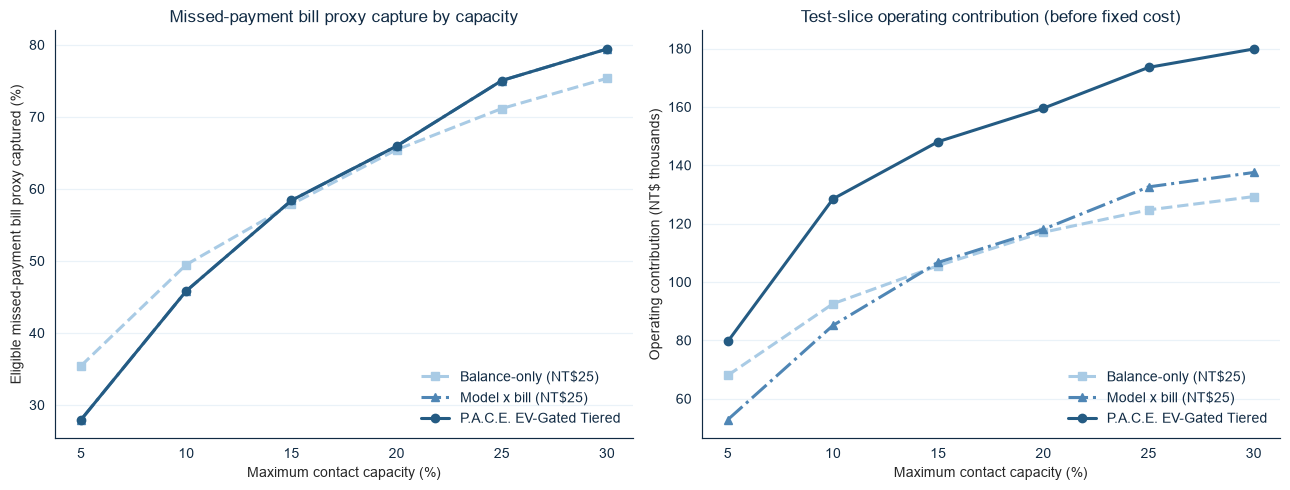

Eligible accounts with EV(Prevent) > 0: 2,335 of 3,151 | capacity cap = 945 accounts -> EV gate is NOT binding; the capacity cap decides who is contacted.


In [20]:
# 8.1 Capacity sweep & EV-gated tiered optimisation (held-out test cohort)

# EDIT THESE VALUES using bank portfolio / pilot evidence before treating this as a forecast.
FINANCIAL_ASSUMPTIONS = {
    "roll_to_90dpd": 0.20,               # Assumed share of next-month missed-payment exposure progressing to 90+ DPD
    "lgd": 0.50,                         # Assumed loss severity (illustrative; the Basel CRE32 50% QRRE figure is a regulatory floor, not a Taiwan estimate)
    "uniform_effectiveness": 0.10,       # Assumed effectiveness for the flat-channel baseline
    "uniform_contact_cost_ntd": 25.0,    # Assumed cost per contact for the flat-channel baseline
    "tier1_assist_cap": 0.10,            # Max share of eligible book routed to high-touch Assist
    "tier1_contact_cost_ntd": 35.0,      # High-touch Assist call / support cost per account
    "tier1_effectiveness": 0.15,         # Assumed effectiveness for Assist outreach
    "tier2_contact_cost_ntd": 5.0,       # Low-friction Prevent digital / SMS nudge cost per account
    "tier2_effectiveness": 0.08,         # Conservative assumed effectiveness for digital nudge
    "fixed_program_cost_ntd": 100_000,   # One-time setup / scoring & workflow build CAPEX
    "annual_platform_opex_ntd": 25_000,  # Annual monitoring, retraining & platform maintenance OPEX
    "annual_cycles": 12                  # Monthly billing cycles per year (steady-state run-rate)
}

def validate_financial_assumptions(inputs):
    prob_keys = {
        "roll_to_90dpd", "lgd", "uniform_effectiveness",
        "tier1_assist_cap", "tier1_effectiveness", "tier2_effectiveness"
    }
    for key, value in inputs.items():
        if key in prob_keys and not 0 <= value <= 1:
            raise ValueError(f"{key} must be between 0 and 1.")
        if value < 0:
            raise ValueError(f"{key} cannot be negative.")

validate_financial_assumptions(FINANCIAL_ASSUMPTIONS)

def compute_tier_evs(df_in, inputs):
    """Compute ex-ante expected net value per account for Assist (Tier 1) and Prevent (Tier 2)."""
    out = df_in.copy()
    risk_multiplier = inputs["roll_to_90dpd"] * inputs["lgd"]
    expected_baseline_loss = out["MODEL_SCORE"] * out["POSITIVE_BILL_PROXY"] * risk_multiplier

    out["EV_UNIFORM"] = (
        expected_baseline_loss * inputs["uniform_effectiveness"]
        - inputs["uniform_contact_cost_ntd"]
    )
    out["EV_T1_ASSIST"] = (
        expected_baseline_loss * inputs["tier1_effectiveness"]
        - inputs["tier1_contact_cost_ntd"]
    )
    out["EV_T2_PREVENT"] = (
        expected_baseline_loss * inputs["tier2_effectiveness"]
        - inputs["tier2_contact_cost_ntd"]
    )
    out["INCREMENTAL_T1_OVER_T2"] = out["EV_T1_ASSIST"] - out["EV_T2_PREVENT"]
    return out

def select_cohort_strategy(df_scored, strategy, capacity, inputs):
    """Select accounts under flat-ranking or EV-gated Tiered P.A.C.E. at a given capacity cap."""
    n_cap = max(1, int(np.floor(len(df_scored) * capacity)))

    if strategy == "balance_uniform":
        selected = df_scored.nlargest(n_cap, "POSITIVE_BILL_PROXY").copy()
        selected["ASSIGNED_TIER"] = "Uniform"
        selected["UNIT_COST"] = inputs["uniform_contact_cost_ntd"]
        selected["APPLIED_EFF"] = inputs["uniform_effectiveness"]
        return selected

    if strategy == "model_uniform":
        selected = df_scored.nlargest(n_cap, "MODEL_PRIORITY_SCORE").copy()
        selected["ASSIGNED_TIER"] = "Uniform"
        selected["UNIT_COST"] = inputs["uniform_contact_cost_ntd"]
        selected["APPLIED_EFF"] = inputs["uniform_effectiveness"]
        return selected

    if strategy == "pace_ev_tiered":
        # Tier 1 (Assist): only accounts where T1 is positive-EV and beats T2 net of extra cost.
        t1_cap_n = min(n_cap, int(np.floor(len(df_scored) * inputs["tier1_assist_cap"])))
        t1_eligible = df_scored.loc[
            (df_scored["EV_T1_ASSIST"] > 0) & (df_scored["INCREMENTAL_T1_OVER_T2"] > 0)
        ].nlargest(t1_cap_n, "EV_T1_ASSIST").copy()
        t1_eligible["ASSIGNED_TIER"] = "Tier 1: Assist"
        t1_eligible["UNIT_COST"] = inputs["tier1_contact_cost_ntd"]
        t1_eligible["APPLIED_EFF"] = inputs["tier1_effectiveness"]

        # Tier 2 (Prevent): remaining budget up to n_cap, strictly EV_T2 > 0.
        remaining_cap = max(0, n_cap - len(t1_eligible))
        remaining_pool = df_scored.drop(index=t1_eligible.index)
        t2_eligible = remaining_pool.loc[
            remaining_pool["EV_T2_PREVENT"] > 0
        ].nlargest(remaining_cap, "EV_T2_PREVENT").copy()
        t2_eligible["ASSIGNED_TIER"] = "Tier 2: Prevent"
        t2_eligible["UNIT_COST"] = inputs["tier2_contact_cost_ntd"]
        t2_eligible["APPLIED_EFF"] = inputs["tier2_effectiveness"]

        return pd.concat([t1_eligible, t2_eligible], axis=0)

    raise ValueError(f"Unknown strategy: {strategy}")

def evaluate_operating_contribution(selected, total_missed_proxy, inputs):
    """Evaluate test-slice identification and variable operating contribution (excl. fixed CAPEX)."""
    missed = selected.loc[selected[TARGET].eq(1)]
    risk_mult = inputs["roll_to_90dpd"] * inputs["lgd"]
    observed_proxy = missed["POSITIVE_BILL_PROXY"].sum()
    avoided_loss = (missed["POSITIVE_BILL_PROXY"] * risk_mult * missed["APPLIED_EFF"]).sum()
    var_cost = selected["UNIT_COST"].sum()
    op_contrib = avoided_loss - var_cost
    return {
        "Accounts contacted": int(len(selected)),
        "Missed-payment accounts": int(len(missed)),
        "Missed-payment rate": selected[TARGET].mean() if len(selected) else 0.0,
        "Missed bill proxy (NT$)": observed_proxy,
        "Bill proxy share": observed_proxy / total_missed_proxy if total_missed_proxy else np.nan,
        "Avoided loss (NT$)": avoided_loss,
        "Variable cost (NT$)": var_cost,
        "Operating contribution (NT$)": op_contrib
    }

scored_test = compute_tier_evs(eligible_test, FINANCIAL_ASSUMPTIONS)
total_test_missed_proxy = scored_test.loc[scored_test[TARGET].eq(1), "POSITIVE_BILL_PROXY"].sum()

capacities = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]
strategy_labels = {
    "balance_uniform": "Balance-only (Uniform NT$25)",
    "model_uniform": "Model x bill (Uniform NT$25)",
    "pace_ev_tiered": "P.A.C.E. EV-Gated Tiered"
}

sweep_rows = []
for cap in capacities:
    for strat_key, strat_name in strategy_labels.items():
        sel = select_cohort_strategy(scored_test, strat_key, cap, FINANCIAL_ASSUMPTIONS)
        metrics = evaluate_operating_contribution(sel, total_test_missed_proxy, FINANCIAL_ASSUMPTIONS)
        metrics["Capacity cap"] = cap
        metrics["Strategy"] = strat_name
        metrics["Strategy_key"] = strat_key
        sweep_rows.append(metrics)

sweep_df = pd.DataFrame(sweep_rows)

display_sweep = sweep_df.loc[sweep_df["Capacity cap"].isin([0.10, 0.20, 0.30]), [
    "Capacity cap", "Strategy", "Accounts contacted", "Missed-payment accounts",
    "Missed-payment rate", "Bill proxy share", "Avoided loss (NT$)",
    "Variable cost (NT$)", "Operating contribution (NT$)"
]].copy()

display(display_sweep.style.format({
    "Capacity cap": "{:.0%}",
    "Missed-payment rate": "{:.1%}",
    "Bill proxy share": "{:.1%}",
    "Avoided loss (NT$)": "NT${:,.0f}",
    "Variable cost (NT$)": "NT${:,.0f}",
    "Operating contribution (NT$)": "NT${:,.0f}"
}))

# Plot capacity sweep: bill proxy capture & operating contribution
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plot_styles = {
    "balance_uniform": ("Balance-only (NT$25)", LIGHT_BLUE, "--", "s"),
    "model_uniform": ("Model x bill (NT$25)", MEDIUM_BLUE, "-.", "^"),
    "pace_ev_tiered": ("P.A.C.E. EV-Gated Tiered", DARK_BLUE, "-", "o")
}

for key, (label, color, ls, marker) in plot_styles.items():
    sub = sweep_df.loc[sweep_df["Strategy_key"].eq(key)]
    axes[0].plot(
        sub["Capacity cap"] * 100, sub["Bill proxy share"] * 100,
        label=label, color=color, linestyle=ls, marker=marker, linewidth=2.2, markersize=6, zorder=3
    )
    axes[1].plot(
        sub["Capacity cap"] * 100, sub["Operating contribution (NT$)"] / 1000,
        label=label, color=color, linestyle=ls, marker=marker, linewidth=2.2, markersize=6, zorder=3
    )

axes[0].set_title("Missed-payment bill proxy capture by capacity")
axes[0].set_xlabel("Maximum contact capacity (%)")
axes[0].set_ylabel("Eligible missed-payment bill proxy captured (%)")
axes[0].set_xticks([c * 100 for c in capacities])
axes[0].legend(frameon=False, loc="lower right")
style_axis(axes[0])

axes[1].set_title("Test-slice operating contribution (before fixed cost)")
axes[1].set_xlabel("Maximum contact capacity (%)")
axes[1].set_ylabel("Operating contribution (NT$ thousands)")
axes[1].set_xticks([c * 100 for c in capacities])
axes[1].legend(frameon=False, loc="lower right")
style_axis(axes[1])

plt.tight_layout()
plt.show()

# Does the EV gate actually remove accounts at the 30% cap?
n_cap30 = int(np.floor(len(scored_test) * CONTACT_CAPACITY))
n_ev_pos = int((scored_test["EV_T2_PREVENT"] > 0).sum())
print(
    f"Eligible accounts with EV(Prevent) > 0: {n_ev_pos:,} of {len(scored_test):,} | "
    f"capacity cap = {n_cap30:,} accounts -> EV gate "
    f"{'is binding (removes accounts)' if n_ev_pos < n_cap30 else 'is NOT binding; the capacity cap decides who is contacted'}."
)


### 8.5 Portfolio-scale projection (Before vs. After P.A.C.E.)

Using the **same** `Roll = 20%` and `LGD = 50%` assumptions, the table moves through four steps:

1. **Test cohort, uniform contact (NT$25), 1 cycle:** the un-tiered baseline on the held-out slice, carrying the full NT$100,000 set-up cost.
2. **Test cohort, tiered P.A.C.E., 1 cycle:** same accounts, tiered channel economics.
3. **Full eligible book, tiered P.A.C.E., 1 cycle - the conservative floor:** held-out results scaled linearly to all eligible accounts.
4. **Full eligible book, 12 cycles - upper bound only:** assumes new independent exposure each month and Year-1 platform OPEX. It is *not* a forecast.

The stress test is shown for both the floor and the upper bound so decision-makers see the range, not a single flattering number.

,Projection level,Contacts,Baseline loss proxy (NT$),Estimated avoided loss (NT$),Total investment (NT$),Net benefit (NT$),ROI,Break-even avg eff
0,1. Test cohort - uniform NT$25 (1 cycle),945,"NT$1,611,402","NT$161,140","NT$123,625","NT$37,515",30.3%,7.7%
1,2. Test cohort - tiered P.A.C.E. (1 cycle),945,"NT$1,611,402","NT$194,008","NT$114,175","NT$79,833",69.9%,7.1%
2,"3. Full book (22,273 accts) - 1 cycle (FLOOR)","6,680","NT$11,390,273","NT$1,371,357","NT$200,197","NT$1,171,160",585.0%,1.8%
3,4. Full book - 12 cycles (UPPER BOUND only),"80,157","NT$136,683,275","NT$16,456,279","NT$1,327,360","NT$15,128,918",1139.8%,1.0%


Tiered P.A.C.E. cohort composition (cost and effectiveness per tier are ASSUMPTIONS):


,ASSIGNED_TIER,test_accounts,missed_accounts,missed_rate,unit_cost_ntd,assumed_eff,full_book_accounts_per_cycle
0,Tier 1: Assist,315,44,14.0%,NT$35,15%,"2,227"
1,Tier 2: Prevent,630,87,13.8%,NT$5,8%,"4,453"



FINANCIAL SCENARIO SUMMARY (illustrative assumptions, not a forecast)
FLOOR  - 1 cycle, full eligible book
   Total investment : NT$200,197
   Baseline loss    : NT$11,390,273
   Avoided loss     : NT$1,371,357
   Net benefit      : NT$1,171,160   ROI 585%
   Break-even avg eff: 1.8%
UPPER - 12 cycles (assumes new independent exposure monthly)
   Total investment : NT$1,327,360
   Baseline loss    : NT$136,683,275
   Avoided loss     : NT$16,456,279
   Net benefit      : NT$15,128,918   ROI 1140%
   Break-even avg eff: 1.0%
Floor net benefit vs balance-only ranking at identical tier pricing (ex-ML cost): NT$-89,980


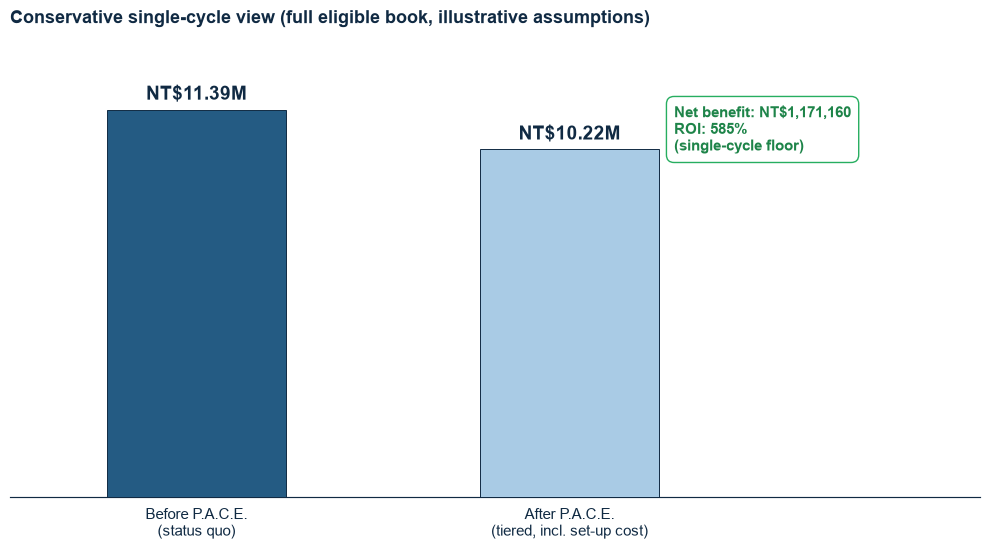

,Projection level,Assumptions,Estimated avoided loss (NT$),Total investment (NT$),Net benefit (NT$),ROI
0,Conservative | Floor (1 cycle),"Roll 15%, LGD 50%, eff 8%/4%","NT$538,909","NT$200,197","NT$338,712",169%
1,Conservative | Upper bound (12 cycles),"Roll 15%, LGD 50%, eff 8%/4%","NT$6,466,905","NT$1,327,360","NT$5,139,545",387%
2,Base | Floor (1 cycle),"Roll 20%, LGD 50%, eff 15%/8%","NT$1,371,357","NT$200,197","NT$1,171,160",585%
3,Base | Upper bound (12 cycles),"Roll 20%, LGD 50%, eff 15%/8%","NT$16,456,279","NT$1,327,360","NT$15,128,918",1140%
4,Upside | Floor (1 cycle),"Roll 30%, LGD 65%, eff 20%/10%","NT$3,502,907","NT$200,197","NT$3,302,710",1650%
5,Upside | Upper bound (12 cycles),"Roll 30%, LGD 65%, eff 20%/10%","NT$42,034,885","NT$1,327,360","NT$40,707,525",3067%


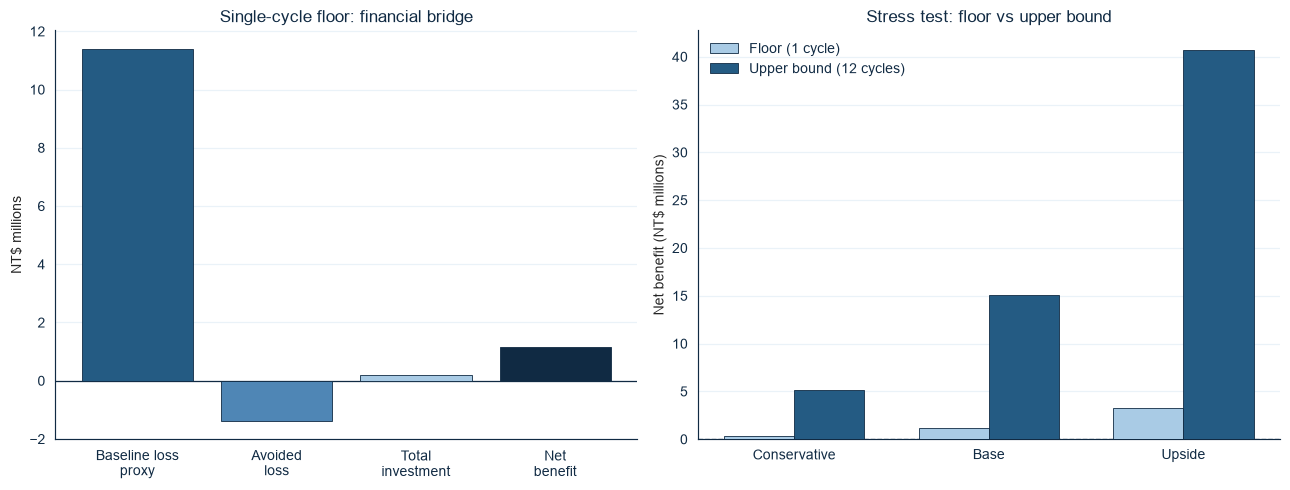

In [21]:
# 8.2 Financial projection: single-cycle floor vs 12-cycle upper bound, plus stress test

FULL_ELIGIBLE_ACCOUNTS = int(eligible_mask.sum())
PORTFOLIO_SCALE = FULL_ELIGIBLE_ACCOUNTS / len(eligible_test)
ANNUAL_CYCLES = FINANCIAL_ASSUMPTIONS["annual_cycles"]
CAPEX_SETUP = FINANCIAL_ASSUMPTIONS["fixed_program_cost_ntd"]
ANNUAL_PLATFORM_OPEX = FINANCIAL_ASSUMPTIONS["annual_platform_opex_ntd"]

test_static_sel = select_cohort_strategy(scored_test, "model_uniform", CONTACT_CAPACITY, FINANCIAL_ASSUMPTIONS)
test_tiered_sel = select_cohort_strategy(scored_test, "pace_ev_tiered", CONTACT_CAPACITY, FINANCIAL_ASSUMPTIONS)
test_balance_sel = select_cohort_strategy(scored_test, "balance_uniform", CONTACT_CAPACITY, FINANCIAL_ASSUMPTIONS)

def project_financials(selected_df, label, scale_factor, cycles, fixed_cost,
                       roll_rate, lgd, eff_override=None):
    """Scenario arithmetic for a selected cohort at a given scale, horizon and stress setting."""
    missed = selected_df.loc[selected_df[TARGET].eq(1)]
    observed_proxy = missed["POSITIVE_BILL_PROXY"].sum() * scale_factor * cycles
    baseline_loss = observed_proxy * roll_rate * lgd
    if eff_override is None:
        eff_series = missed["APPLIED_EFF"]
    else:
        eff_series = missed["ASSIGNED_TIER"].map(eff_override).fillna(missed["APPLIED_EFF"])
    avoided_loss = (missed["POSITIVE_BILL_PROXY"] * roll_rate * lgd * eff_series).sum() * scale_factor * cycles
    var_cost = selected_df["UNIT_COST"].sum() * scale_factor * cycles
    total_investment = var_cost + fixed_cost
    return {
        "Projection level": label,
        "Contacts": int(round(len(selected_df) * scale_factor * cycles)),
        "Baseline loss proxy (NT$)": baseline_loss,
        "Estimated avoided loss (NT$)": avoided_loss,
        "Variable contact cost (NT$)": var_cost,
        "Fixed / platform cost (NT$)": fixed_cost,
        "Total investment (NT$)": total_investment,
        "Residual loss (NT$)": baseline_loss - avoided_loss,
        "Total burden after (NT$)": baseline_loss - avoided_loss + total_investment,
        "Net benefit (NT$)": avoided_loss - total_investment,
        "ROI": (avoided_loss - total_investment) / total_investment if total_investment > 0 else np.nan,
        "Break-even avg eff": total_investment / baseline_loss if baseline_loss > 0 else np.nan,
    }

base_roll = FINANCIAL_ASSUMPTIONS["roll_to_90dpd"]
base_lgd = FINANCIAL_ASSUMPTIONS["lgd"]

progression_rows = [
    project_financials(test_static_sel, "1. Test cohort - uniform NT$25 (1 cycle)",
                       1.0, 1, CAPEX_SETUP, base_roll, base_lgd),
    project_financials(test_tiered_sel, "2. Test cohort - tiered P.A.C.E. (1 cycle)",
                       1.0, 1, CAPEX_SETUP, base_roll, base_lgd),
    project_financials(test_tiered_sel, f"3. Full book ({FULL_ELIGIBLE_ACCOUNTS:,} accts) - 1 cycle (FLOOR)",
                       PORTFOLIO_SCALE, 1, CAPEX_SETUP, base_roll, base_lgd),
    project_financials(test_tiered_sel, f"4. Full book - {ANNUAL_CYCLES} cycles (UPPER BOUND only)",
                       PORTFOLIO_SCALE, ANNUAL_CYCLES, CAPEX_SETUP + ANNUAL_PLATFORM_OPEX, base_roll, base_lgd),
]
progression_df = pd.DataFrame(progression_rows)
fmt_money = "NT${:,.0f}"
display(progression_df[[
    "Projection level", "Contacts", "Baseline loss proxy (NT$)", "Estimated avoided loss (NT$)",
    "Total investment (NT$)", "Net benefit (NT$)", "ROI", "Break-even avg eff"
]].style.format({
    "Contacts": "{:,}", "Baseline loss proxy (NT$)": fmt_money, "Estimated avoided loss (NT$)": fmt_money,
    "Total investment (NT$)": fmt_money, "Net benefit (NT$)": fmt_money,
    "ROI": "{:.1%}", "Break-even avg eff": "{:.1%}"
}))

tier_breakdown = (
    test_tiered_sel.groupby("ASSIGNED_TIER", observed=True)
    .agg(test_accounts=(TARGET, "size"), missed_accounts=(TARGET, "sum"),
         missed_rate=(TARGET, "mean"), unit_cost_ntd=("UNIT_COST", "first"),
         assumed_eff=("APPLIED_EFF", "first"))
    .reset_index()
)
tier_breakdown["full_book_accounts_per_cycle"] = (tier_breakdown["test_accounts"] * PORTFOLIO_SCALE).round(0).astype(int)
print("Tiered P.A.C.E. cohort composition (cost and effectiveness per tier are ASSUMPTIONS):")
display(tier_breakdown.style.format({
    "missed_rate": "{:.1%}", "unit_cost_ntd": "NT${:,.0f}", "assumed_eff": "{:.0%}",
    "full_book_accounts_per_cycle": "{:,}"
}))

# Benchmark: balance-only ranking given the SAME tiered channel pricing, no ML costs
test_balance_tiered = test_balance_sel.copy()
n_t1_bal = min(len(test_balance_sel), int(np.floor(len(scored_test) * FINANCIAL_ASSUMPTIONS["tier1_assist_cap"])))
test_balance_tiered["ASSIGNED_TIER"] = "Tier 2: Prevent"
test_balance_tiered["UNIT_COST"] = FINANCIAL_ASSUMPTIONS["tier2_contact_cost_ntd"]
test_balance_tiered["APPLIED_EFF"] = FINANCIAL_ASSUMPTIONS["tier2_effectiveness"]
t1_bal_idx = test_balance_tiered.index[:n_t1_bal]
test_balance_tiered.loc[t1_bal_idx, "ASSIGNED_TIER"] = "Tier 1: Assist"
test_balance_tiered.loc[t1_bal_idx, "UNIT_COST"] = FINANCIAL_ASSUMPTIONS["tier1_contact_cost_ntd"]
test_balance_tiered.loc[t1_bal_idx, "APPLIED_EFF"] = FINANCIAL_ASSUMPTIONS["tier1_effectiveness"]

floor_pace = progression_rows[2]
upper_pace = progression_rows[3]
floor_bal = project_financials(test_balance_tiered, "balance floor", PORTFOLIO_SCALE, 1, 0.0, base_roll, base_lgd)
floor_inc = floor_pace["Net benefit (NT$)"] - floor_bal["Net benefit (NT$)"]

print("\nFINANCIAL SCENARIO SUMMARY (illustrative assumptions, not a forecast)")
print(74 * "=")
for tag, r in [("FLOOR  - 1 cycle, full eligible book", floor_pace),
               (f"UPPER - {ANNUAL_CYCLES} cycles (assumes new independent exposure monthly)", upper_pace)]:
    print(tag)
    print(f"   Total investment : NT${r['Total investment (NT$)']:,.0f}")
    print(f"   Baseline loss    : NT${r['Baseline loss proxy (NT$)']:,.0f}")
    print(f"   Avoided loss     : NT${r['Estimated avoided loss (NT$)']:,.0f}")
    print(f"   Net benefit      : NT${r['Net benefit (NT$)']:,.0f}   ROI {r['ROI']:.0%}")
    print(f"   Break-even avg eff: {r['Break-even avg eff']:.1%}")
print(f"Floor net benefit vs balance-only ranking at identical tier pricing (ex-ML cost): NT${floor_inc:+,.0f}")
print(74 * "=")

# Chart 1 - Before vs After for the conservative single-cycle floor (zero-anchored axis)
fig, ax = plt.subplots(figsize=(10, 5.6))
vals = [floor_pace["Baseline loss proxy (NT$)"], floor_pace["Total burden after (NT$)"]]
ax.bar([0, 1], vals, color=[DARK_BLUE, LIGHT_BLUE], edgecolor=DARK_NAVY, linewidth=0.7, width=0.48, zorder=3)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Before P.A.C.E.\n(status quo)", "After P.A.C.E.\n(tiered, incl. set-up cost)"], fontsize=11)
ax.set_yticks([])
for sp_ in ["top", "right", "left"]:
    ax.spines[sp_].set_visible(False)
ax.spines["bottom"].set_color(DARK_NAVY)
for i_, v_ in enumerate(vals):
    ax.text(i_, v_ + max(vals) * 0.015, f"NT${v_/1e6:,.2f}M", ha="center", va="bottom",
            fontsize=14, fontweight="bold", color=DARK_NAVY)
ax.text(1.28, sum(vals) / 2,
        f"Net benefit: NT${floor_pace['Net benefit (NT$)']:,.0f}\nROI: {floor_pace['ROI']:.0%}\n(single-cycle floor)",
        ha="left", va="center", fontsize=11, color="#1E8449", fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="#27AE60"))
ax.set_xlim(-0.5, 2.1)
ax.set_ylim(0, max(vals) * 1.18)
ax.set_title("Conservative single-cycle view (full eligible book, illustrative assumptions)",
             fontsize=13, fontweight="bold", color=DARK_NAVY, loc="left", pad=12)
plt.tight_layout()
plt.show()

# Stress test across floor and upper bound
stress_scenarios = [
    ("Conservative", 0.15, 0.50, {"Tier 1: Assist": 0.08, "Tier 2: Prevent": 0.04}),
    ("Base", 0.20, 0.50, {"Tier 1: Assist": 0.15, "Tier 2: Prevent": 0.08}),
    ("Upside", 0.30, 0.65, {"Tier 1: Assist": 0.20, "Tier 2: Prevent": 0.10}),
]
stress_rows = []
for name, roll, lgd_, eff in stress_scenarios:
    for horizon, cycles, fixed in [("Floor (1 cycle)", 1, CAPEX_SETUP),
                                   (f"Upper bound ({ANNUAL_CYCLES} cycles)", ANNUAL_CYCLES, CAPEX_SETUP + ANNUAL_PLATFORM_OPEX)]:
        r = project_financials(test_tiered_sel, f"{name} | {horizon}", PORTFOLIO_SCALE, cycles, fixed,
                               roll, lgd_, eff_override=eff)
        r["Scenario"], r["Horizon"] = name, horizon
        r["Assumptions"] = f"Roll {roll:.0%}, LGD {lgd_:.0%}, eff {eff['Tier 1: Assist']:.0%}/{eff['Tier 2: Prevent']:.0%}"
        stress_rows.append(r)
stress_df = pd.DataFrame(stress_rows)
display(stress_df[["Projection level", "Assumptions", "Estimated avoided loss (NT$)",
                   "Total investment (NT$)", "Net benefit (NT$)", "ROI"]].style.format({
    "Estimated avoided loss (NT$)": fmt_money, "Total investment (NT$)": fmt_money,
    "Net benefit (NT$)": fmt_money, "ROI": "{:.0%}"}))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
bridge_labels = ["Baseline loss\nproxy", "Avoided\nloss", "Total\ninvestment", "Net\nbenefit"]
bridge_vals = [floor_pace["Baseline loss proxy (NT$)"], -floor_pace["Estimated avoided loss (NT$)"],
               floor_pace["Total investment (NT$)"], floor_pace["Net benefit (NT$)"]]
axes[0].bar(bridge_labels, [v / 1e6 for v in bridge_vals],
            color=[DARK_BLUE, MEDIUM_BLUE, LIGHT_BLUE, DARK_NAVY], edgecolor=DARK_NAVY, linewidth=0.6, zorder=3)
axes[0].axhline(0, color=DARK_NAVY, linewidth=0.9)
axes[0].set_ylabel("NT$ millions")
axes[0].set_title("Single-cycle floor: financial bridge")
style_axis(axes[0])

x = np.arange(3); w = 0.36
for k, (hz, colr) in enumerate([("Floor (1 cycle)", LIGHT_BLUE), (f"Upper bound ({ANNUAL_CYCLES} cycles)", DARK_BLUE)]):
    sub = stress_df.loc[stress_df["Horizon"] == hz]
    axes[1].bar(x + (k - 0.5) * w, sub["Net benefit (NT$)"] / 1e6, w, color=colr,
                edgecolor=DARK_NAVY, linewidth=0.6, label=hz, zorder=3)
axes[1].set_xticks(x)
axes[1].set_xticklabels([s_[0] for s_ in stress_scenarios])
axes[1].axhline(0, color=DARK_NAVY, linewidth=0.9, linestyle="--")
axes[1].set_ylabel("Net benefit (NT$ millions)")
axes[1].set_title("Stress test: floor vs upper bound")
axes[1].legend(frameon=False)
style_axis(axes[1])
plt.tight_layout()
plt.show()


### 8.6 Key financial takeaways for decision-makers

**1. The earlier "modest" projection was mostly a scale effect.** Evaluating only the held-out slice (about 945 contacts, one month) while charging the full NT$100,000 set-up cost compresses the result to a net benefit of NT$37,515 (30% ROI). Scaling the same cohort behaviour to the full eligible book (22,273 accounts) for **one cycle** gives a net benefit of about **NT$1.17M (585% ROI)** under the base assumptions. This single-cycle figure is the number to lead with.

**2. Treat the 12-cycle figure as an upper bound only.** The label observes a single next-month outcome. Multiplying by 12 assumes each month brings new, independent exposure of the same size, but many accounts recur, so exposure overlaps. The resulting NT$15.1M (1,140% ROI) is a ceiling, not an estimate.

**3. The result survives pessimistic assumptions, but depends on them.** Under the conservative scenario (15% roll, 50% LGD, 8% / 4% effectiveness) the single-cycle floor is still positive (about NT$339K, 169% ROI). Break-even average effectiveness is only about 1.8% at the floor. Roll rate, LGD and intervention effectiveness are **assumptions**, so the pilot in Section 9 must measure them.

**4. Where the model genuinely adds value, and where it does not.**
- *Identification:* across 8 independent grouped splits, the P.A.C.E. priority ranking finds about **+36 more missed-payment accounts** and about **+NT$1.07M more missed bill proxy** than balance-only ranking, and wins in **8 of 8 splits**.
- *Financial scenario:* when balance-only ranking is given the **same tier pricing and effectiveness**, the scenario net benefit is essentially the same (balance-only is about NT$90K higher per cycle). The financial result is driven by outreach design and exposure, not by the model alone. The model's advantage is **finding the right customers**, which only a controlled pilot can convert into avoided loss.
- *Risk vs exposure ranking:* ranking by risk score alone finds the most missed payments (lift about 1.7x vs about 1.05x for the exposure-weighted priority), while the exposure-weighted priority captures far more bill value. Choose according to the objective: customer coverage or balance at risk.

**5. Tiering and EV gating are operating design, not proven gains.** At the 30% cap, about 2,300 eligible test accounts have positive expected value but only 945 can be contacted, so the **EV gate does not bind**: the capacity cap decides who is contacted. Tier costs and tier effectiveness are assumptions. They illustrate the design, not a measured uplift.

**6. Simpler is competitive.** Inside the eligible population, logistic regression (AUC about 0.67, lift about 1.7x) is close to gradient boosting (AUC about 0.69, lift about 1.7x), and removing `AGE` and `EDUCATION` costs essentially nothing. A transparent scorecard without demographic-adjacent features is a defensible production candidate, and a simple behavioural rule already reaches about 1.4x lift.

## 9. Pilot design: how to validate P.A.C.E.

### Objective

Test whether preventive outreach to model-prioritised early-warning accounts reduces subsequent serious delinquency versus business as usual.

### Suggested design

1. **Eligibility:** `PAY_1 <= 0`, positive statement-balance proxy, and no unresolved data-quality flag.
2. **Selection:** use the model to prioritise within the available outreach capacity.
3. **Randomisation:** randomly assign eligible selected accounts to treatment and control groups, stratified by risk band where practical.
4. **Treatment:** approved reminder, payment-date prompt, self-service payment information, or access to support.
5. **Primary outcome:** 90+ DPD within a pre-agreed follow-up window. Track 30- and 60-day transitions as intermediate outcomes.
6. **Secondary outcomes:** payment amount, cure rate, complaints, opt-outs, contact success, and cost per contacted account.
7. **Decision:** scale only if the treatment/control difference is statistically and commercially meaningful, with acceptable customer-treatment outcomes.

### Minimum additional data required

| Data | Why it is required |
|---|---|
| Monthly DPD / delinquency history | Measure 30/60/90+ DPD transitions and cure rates. |
| Account-level EAD / statement exposure at default | Measure exposure when delinquency occurs. |
| Charge-off and recovery history | Estimate realised loss severity / LGD. |
| Contact history and randomised assignment | Attribute outcomes to the intervention and avoid over-contacting. |
| Contact and technology costs | Calculate net benefit and ROI. |
| Complaints, opt-outs, and hardship outcomes | Monitor customer impact and unintended harm. |

## 10. Limitations, assumptions & governance

1. **Historical data:** Taiwan, April–September 2005. Results should not be assumed to represent a current issuer portfolio.
2. **Target definition:** the model predicts the dataset's next-month missed-payment label; it does not predict regulatory default, 90+ DPD, or charge-off.
3. **No causal evidence:** behavioural patterns and model rankings do not prove why a customer missed payment or whether outreach changes the outcome.
4. **Exposure proxy:** `max(BILL_AMT1, 0)` is a statement-balance proxy, not validated EAD or total customer indebtedness.
5. **No financial-loss inputs:** the dataset lacks roll-forward, charge-off, recovery, LGD, contact response, and operating costs.
6. **Duplicate profiles:** identical predictor profiles are grouped during splitting. The dataset does not provide a verified persistent customer identifier for longitudinal analysis.
7. **Dormant patterns:** unusual combinations of non-positive bills, zero payments, and repayment-status codes require source-definition review.
8. **Fair customer treatment:** the score should support low-friction assistance and prioritisation only. A Taiwanese issuer must complete its own legal, risk, privacy, and customer-treatment review before any deployment.
9. **Financial scenario assumptions:** roll-to-90+ DPD, LGD, intervention effectiveness, contact cost, and fixed programme cost in Section 8 are editable illustrative inputs, not empirically validated Taiwan portfolio benchmarks. Replace them with issuer data and controlled-pilot results.
10. **Model governance:** monitor calibration, ranking stability, segment performance, drift, and customer outcomes before operational use.
11. **Discrimination inside the target population is moderate.** The all-account ROC-AUC (about 0.78) is inflated by easy-to-rank `PAY_1 >= 2` accounts. Inside the eligible `PAY_1 <= 0` population the AUC is about 0.67-0.69 (Section 6.1). The score is well calibrated but should be described as a prioritisation aid, not a precise predictor.
12. **Ranking choice changes what is optimised.** Exposure-weighted ranking maximises balance at risk; risk-only ranking maximises the number of missed payments found (Section 6.2). Neither is validated against avoided loss.
13. **Annualised figures overlap.** The 12-cycle projection assumes new independent exposure each month and is an upper bound.
14. **Results depend on the split and on library versions.** Single-split numbers shift between environments; the multi-split means in Section 6.2 are the more reliable reference.

## 11. References

1. Yeh, I-C. (2009). *Default of Credit Card Clients* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55S3H. Dataset documentation: https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients
2. Yeh, I-C., & Lien, C-H. (2009). The comparisons of data mining techniques for the predictive accuracy of probability of default of credit card clients. *Expert Systems with Applications, 36*(2), 2473–2480.
3. International Monetary Fund. (2026). *IFRS 9 Implementation from the Perspective of Banking Supervisors*. Technical Notes and Manuals. https://www.imf.org/-/media/files/publications/tnm/2026/english/tnmea2026004.pdf

**Reference policy:** The dataset context remains Taiwan-specific. The IMF source is used only for the general expected-credit-loss measurement components; no foreign regulatory thresholds or foreign collection-effect assumptions are imported into the Taiwan case.